## Model-based
pymaftools: https://github.com/xu62u4u6/pymaftools/blob/main/pymaftools/core/Clustering.py

In [1]:
#conda activate TLS
#pip uninstall pymaftools
#pip install --no-cache-dir git+https://github.com/xu62u4u6/pymaftools.git
from pymaftools import *
import sys
sys.path.append("/home/data/data_YM313112004/TLS_model/utils/")
random_seed = 42

In [2]:
# 不用重啟 kernel，Notebook 就會自動載入更新後的函式
%load_ext autoreload
%autoreload 2

### Load Data

In [14]:
from pymaftools import PivotTable
cancer_type = "PAAD"
PAAD_rna = PivotTable.read_sqlite(f"/home/data/data_YM313112004/TLS_model/results/{cancer_type}/table/rna_table.sqlite")
PAAD_meth = PivotTable.read_sqlite(f"/home/data/data_YM313112004/TLS_model/results/{cancer_type}/table/meth_table.sqlite")
PAAD_mut = PivotTable.read_sqlite(f"/home/data/data_YM313112004/TLS_model/results/{cancer_type}/table/mutation_table.sqlite")
PAAD_cnv = PivotTable.read_sqlite(f"/home/data/data_YM313112004/TLS_model/results/{cancer_type}/table/cnv_cluster_table_{random_seed}.sqlite")  # 已經 cluster

[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/PAAD/table/rna_table.sqlite
[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/PAAD/table/meth_table.sqlite
[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/PAAD/table/mutation_table.sqlite
[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/PAAD/table/cnv_cluster_table_42.sqlite


In [15]:
train_samples = PAAD_rna.sample_metadata[f"split_{random_seed}"] == "train"
test_samples = PAAD_rna.sample_metadata[f"split_{random_seed}"] == "test"
rna_train = PAAD_rna.subset(samples=train_samples)
rna_test = PAAD_rna.subset(samples=test_samples)

train_samples = PAAD_meth.sample_metadata[f"split_{random_seed}"] == "train"
test_samples = PAAD_meth.sample_metadata[f"split_{random_seed}"] == "test"
meth_train = PAAD_meth.subset(samples=train_samples)
meth_test = PAAD_meth.subset(samples=test_samples)

train_samples = PAAD_mut.sample_metadata[f"split_{random_seed}"] == "train"
test_samples = PAAD_mut.sample_metadata[f"split_{random_seed}"] == "test"
mut_train = PAAD_mut.subset(samples=train_samples)
mut_test = PAAD_mut.subset(samples=test_samples)

train_samples = PAAD_cnv.sample_metadata[f"split_{random_seed}"] == "train"
test_samples = PAAD_cnv.sample_metadata[f"split_{random_seed}"] == "test"
cnv_train = PAAD_cnv.subset(samples=train_samples)
cnv_test = PAAD_cnv.subset(samples=test_samples)

In [16]:
# Independent datasets
CHOL_rna = PivotTable.read_sqlite(f"/home/data/data_YM313112004/TLS_model/results/CHOL/table/rna_table.sqlite")
CHOL_meth = PivotTable.read_sqlite(f"/home/data/data_YM313112004/TLS_model/results/CHOL/table/meth_table.sqlite")
CHOL_mut = PivotTable.read_sqlite(f"/home/data/data_YM313112004/TLS_model/results/CHOL/table/mutation_table.sqlite")
CHOL_cnv = PivotTable.read_sqlite(f"/home/data/data_YM313112004/TLS_model/results/CHOL/table/cnv_table.sqlite")  # 尚未分群

STAD_rna = PivotTable.read_sqlite(f"/home/data/data_YM313112004/TLS_model/results/STAD/table/rna_table.sqlite")
STAD_meth = PivotTable.read_sqlite(f"/home/data/data_YM313112004/TLS_model/results/STAD/table/meth_table.sqlite")
STAD_mut = PivotTable.read_sqlite(f"/home/data/data_YM313112004/TLS_model/results/STAD/table/mutation_table.sqlite")
STAD_cnv = PivotTable.read_sqlite(f"/home/data/data_YM313112004/TLS_model/results/STAD/table/cnv_table.sqlite")  # 尚未分群

[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/CHOL/table/rna_table.sqlite
[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/CHOL/table/meth_table.sqlite
[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/CHOL/table/mutation_table.sqlite
[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/CHOL/table/cnv_table.sqlite
[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/STAD/table/rna_table.sqlite
[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/STAD/table/meth_table.sqlite
[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/STAD/table/mutation_table.sqlite
[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/STAD/table/cnv_table.sqlite


### Assign Cluster

In [17]:
cnv_train.feature_metadata

,unique_cytoband,ids_in_cluster,genes_in_cluster,gene_count
feature,,,,
0,"15q21.3,15q22.1,15q22.2,15q22.31,15q22.33,15q2...","51187,5873,101928527,9488,9236,145788,26108,28...","RSL24D1,RAB27A,PIGBOS1,PIGB,CCPG1,C15orf65,PYG...",317
1,"7p22.3,7p22.2,7p22.1,7p21.3,7p21.2,7p21.1,7p15...","56975,5154,5575,54919,23353,51608,11033,90639,...","FAM20C,PDGFA,PRKAR1B,DNAAF5,SUN1,GET4,ADAP1,CO...",336
2,"16p13.3,16p13.2,16p13.13,16p13.12,16p13.11,16p...","83886,23524,260429,360226,10942,124220,64063,1...","PRSS27,SRRM2,PRSS33,PRSS41,PRSS21,ZG16B,PRSS22...",294
3,"9p24.3,9p24.2,9p24.1,9p23,9p22.3,9p21.3,9p21.2...","55871,2298,81704,23189,1761,58524,10655,6595,7...","CBWD1,FOXD4,DOCK8,KANK1,DMRT1,DMRT3,DMRT2,SMAR...",512
4,"17q22,17q23.1,17q23.2,17q23.3,17q24.1,17q24.2,...","84643,10040,1353,252983,3131,23531,55273,58488...","KIF2B,TOM1L1,COX11,STXBP4,HLF,MMD,TMEM100,PCTP...",319
...,...,...,...,...
160,11q11,"219428,219429,81300,219431","OR4C16,OR4C11,OR4P4,OR4S2",4
161,10q26.13,1755,DMBT1,1
162,18p11.31,"642597,7541,23136,645369,91133,79822","AKAIN1,ZBTB14,EPB41L3,TMEM200C,L3MBTL4,ARHGAP28",6


In [18]:
## Clustering for CHOL independent dataset
cluster_labels_df = pd.read_csv(f"/home/data/data_YM313112004/TLS_model/results/{cancer_type}/clustering/best_k_cluster_labels_{random_seed}.csv", index_col=0)
if "cluster" in cluster_labels_df.columns:
    gene_cluster_series = cluster_labels_df["cluster"].astype(int)
else:
    gene_cluster_series = cluster_labels_df.iloc[:, 0].astype(int)

# map clustering results
mapping = gene_cluster_series.reindex(CHOL_cnv.index)
CHOL_cnv.feature_metadata["cluster"] = mapping

# summarize clusters
cnv_tmp = pd.DataFrame(CHOL_cnv)
cnv_tmp["cluster"] = mapping.loc[cnv_tmp.index].values

# to cluster table
CHOL_cnv_cluster = PivotTable(cnv_tmp.groupby("cluster").mean())
CHOL_cnv_cluster.sample_metadata = CHOL_cnv.sample_metadata
CHOL_cnv_cluster.feature_metadata["unique_cytoband"] = (
    CHOL_cnv.feature_metadata.groupby("cluster")["Cytoband"]
    .agg(lambda s: ",".join(pd.Series(s).dropna().astype(str).unique()))
)
CHOL_cnv_cluster.feature_metadata["ids_in_cluster"] = (
    CHOL_cnv.feature_metadata.groupby("cluster")["Gene ID"]
    .agg(lambda s: ",".join(pd.Series(s).dropna().astype(str).unique()))
)
CHOL_cnv_cluster.feature_metadata["genes_in_cluster"]  = CHOL_cnv.feature_metadata.groupby("cluster").apply(lambda df: ",".join(df.index), include_groups=False)
CHOL_cnv_cluster.feature_metadata["gene_count"] = CHOL_cnv.feature_metadata.groupby("cluster").size()
CHOL_cnv_cluster.feature_metadata

,unique_cytoband,ids_in_cluster,genes_in_cluster,gene_count
cluster,,,,
0,"15q21.3,15q22.1,15q22.2,15q22.31,15q22.33,15q2...","51187,5873,101928527,9488,9236,145788,26108,28...","RSL24D1,RAB27A,PIGBOS1,PIGB,CCPG1,C15orf65,PYG...",317
1,"7p22.3,7p22.2,7p22.1,7p21.3,7p21.2,7p21.1,7p15...","56975,5154,5575,54919,23353,51608,11033,90639,...","FAM20C,PDGFA,PRKAR1B,DNAAF5,SUN1,GET4,ADAP1,CO...",336
2,"16p13.3,16p13.2,16p13.13,16p13.12,16p13.11,16p...","83886,23524,260429,360226,10942,124220,64063,1...","PRSS27,SRRM2,PRSS33,PRSS41,PRSS21,ZG16B,PRSS22...",294
3,"9p24.3,9p24.2,9p24.1,9p23,9p22.3,9p21.3,9p21.2...","55871,2298,81704,23189,1761,58524,10655,6595,7...","CBWD1,FOXD4,DOCK8,KANK1,DMRT1,DMRT3,DMRT2,SMAR...",512
4,"17q22,17q23.1,17q23.2,17q23.3,17q24.1,17q24.2,...","84643,10040,1353,252983,3131,23531,55273,58488...","KIF2B,TOM1L1,COX11,STXBP4,HLF,MMD,TMEM100,PCTP...",319
...,...,...,...,...
160,11q11,"219428,219429,81300,219431","OR4C16,OR4C11,OR4P4,OR4S2",4
161,10q26.13,1755,DMBT1,1
162,18p11.31,"642597,7541,23136,645369,91133,79822","AKAIN1,ZBTB14,EPB41L3,TMEM200C,L3MBTL4,ARHGAP28",6


In [19]:
## Clustering for STAD independent dataset
# map clustering results
mapping = gene_cluster_series.reindex(STAD_cnv.index)
STAD_cnv.feature_metadata["cluster"] = mapping

# summarize clusters
cnv_tmp = pd.DataFrame(STAD_cnv)
cnv_tmp["cluster"] = mapping.loc[cnv_tmp.index].values

# to cluster table
STAD_cnv_cluster = PivotTable(cnv_tmp.groupby("cluster").mean())
STAD_cnv_cluster.sample_metadata = STAD_cnv.sample_metadata
STAD_cnv_cluster.feature_metadata["unique_cytoband"] = (
    STAD_cnv.feature_metadata.groupby("cluster")["Cytoband"]
    .agg(lambda s: ",".join(pd.Series(s).dropna().astype(str).unique()))
)
STAD_cnv_cluster.feature_metadata["ids_in_cluster"] = (
    STAD_cnv.feature_metadata.groupby("cluster")["Gene ID"]
    .agg(lambda s: ",".join(pd.Series(s).dropna().astype(str).unique()))
)
STAD_cnv_cluster.feature_metadata["genes_in_cluster"]  = STAD_cnv.feature_metadata.groupby("cluster").apply(lambda df: ",".join(df.index), include_groups=False)
STAD_cnv_cluster.feature_metadata["gene_count"] = STAD_cnv.feature_metadata.groupby("cluster").size()
STAD_cnv_cluster.feature_metadata

,unique_cytoband,ids_in_cluster,genes_in_cluster,gene_count
cluster,,,,
0,"15q21.3,15q22.1,15q22.2,15q22.31,15q22.33,15q2...","51187,5873,101928527,9488,9236,145788,26108,28...","RSL24D1,RAB27A,PIGBOS1,PIGB,CCPG1,C15orf65,PYG...",317
1,"7p22.3,7p22.2,7p22.1,7p21.3,7p21.2,7p21.1,7p15...","56975,5154,5575,54919,23353,51608,11033,90639,...","FAM20C,PDGFA,PRKAR1B,DNAAF5,SUN1,GET4,ADAP1,CO...",336
2,"16p13.3,16p13.2,16p13.13,16p13.12,16p13.11,16p...","83886,23524,260429,360226,10942,124220,64063,1...","PRSS27,SRRM2,PRSS33,PRSS41,PRSS21,ZG16B,PRSS22...",294
3,"9p24.3,9p24.2,9p24.1,9p23,9p22.3,9p21.3,9p21.2...","55871,2298,81704,23189,1761,58524,10655,6595,7...","CBWD1,FOXD4,DOCK8,KANK1,DMRT1,DMRT3,DMRT2,SMAR...",512
4,"17q22,17q23.1,17q23.2,17q23.3,17q24.1,17q24.2,...","84643,10040,1353,252983,3131,23531,55273,58488...","KIF2B,TOM1L1,COX11,STXBP4,HLF,MMD,TMEM100,PCTP...",319
...,...,...,...,...
160,11q11,"219428,219429,81300,219431","OR4C16,OR4C11,OR4P4,OR4S2",4
161,10q26.13,1755,DMBT1,1
162,18p11.31,"642597,7541,23136,645369,91133,79822","AKAIN1,ZBTB14,EPB41L3,TMEM200C,L3MBTL4,ARHGAP28",6


### Concat and Tree Importance

In [20]:
from model_utils import concat_omics
PAAD_train = concat_omics([rna_train, meth_train, mut_train, cnv_train], keys=["RNA", "Meth", "Mutation", "CNV"], axis=0)
PAAD_test = concat_omics([rna_test, meth_test, mut_test, cnv_test], keys=["RNA", "Meth", "Mutation", "CNV"], axis=0)
PAAD_train

/home/YM313112004/miniconda3/envs/TLS/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


sample,TCGA-2L-AAQA-01A,TCGA-2L-AAQL-01A,TCGA-2J-AAB4-01A,TCGA-IB-A6UG-01A,TCGA-HZ-A77O-01A,TCGA-3A-A9IL-01A,TCGA-2J-AABO-01A,TCGA-H6-8124-01A,TCGA-IB-A7M4-01A,TCGA-FB-A5VM-01A,...,TCGA-US-A77E-01A,TCGA-IB-A5SQ-01A,TCGA-IB-AAUM-01A,TCGA-FB-AAQ3-01A,TCGA-IB-7887-01A,TCGA-3A-A9IH-01A,TCGA-F2-A7TX-01A,TCGA-HZ-7924-01A,TCGA-IB-7890-01A,TCGA-IB-7654-01A
RNA_A1BG,0.193330,0.108892,0.197111,0.081749,0.000000,1.081749,0.159887,0.074231,0.075601,0.224411,...,0.175557,0.179256,0.037031,0.072586,0.059909,0.116099,0.000000,0.059494,0.278698,0.139862
RNA_A1CF,1.845470,1.654161,1.610228,0.901263,0.743472,3.743623,1.724738,0.750092,0.972913,0.224287,...,1.770491,2.363816,1.077175,1.415975,0.974603,0.734048,1.160146,4.186960,1.398898,1.648373
RNA_A2M,7.074512,8.349059,8.484469,7.083435,7.407824,8.176749,9.015322,7.763216,6.653587,8.083053,...,8.398715,9.593737,7.382747,6.919648,7.820449,8.144368,7.819523,9.625054,9.237116,8.575170
RNA_A2ML1,0.214374,0.106616,0.064193,2.738833,2.330128,0.091124,2.903347,2.855591,2.494953,4.071891,...,1.230818,1.167486,0.149259,0.354678,0.240742,3.088057,1.604783,0.050049,4.204876,0.850479
RNA_A3GALT2,0.247077,0.106482,0.000000,0.424062,0.083656,0.334111,0.297485,0.095992,0.000000,0.000000,...,0.171847,0.453544,0.139600,0.000000,0.288063,0.408929,0.469052,0.058247,0.245009,0.122341
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
CNV_160,0.009000,-0.004000,-0.051000,0.214000,0.046000,-0.587000,0.025750,-0.276000,0.005000,-0.029000,...,0.006000,0.000000,0.876000,-0.050000,0.109000,0.033000,0.139000,0.057000,0.015000,0.073000
CNV_161,0.000000,0.170000,-0.016000,-0.353000,-0.660000,-1.016000,-0.661000,-0.642000,-0.583000,-1.001000,...,-0.023000,-0.448000,-0.647000,-0.496000,-0.266000,0.062000,0.164000,-0.017000,0.026000,-0.386000
CNV_162,0.005000,-0.031000,-0.010000,-0.052000,0.471000,-0.009000,0.099000,-0.027000,-0.368000,-0.292000,...,-0.035000,-0.163000,-0.069000,0.026000,-0.006000,-0.308000,-0.220000,-0.024000,-0.336000,-0.014000
CNV_163,-0.701000,0.202000,-1.293000,-1.293000,-1.266000,0.510000,0.051000,-0.705000,0.011000,0.000000,...,0.377000,0.118000,0.007000,-1.293000,0.021000,-0.652000,0.145000,0.030000,-0.311000,0.000000


In [21]:
top_features_rna = np.load(f"/home/data/data_YM313112004/TLS_model/results/{cancer_type}/selected_features/top_features_rna_mrmr_{random_seed}.npy", allow_pickle=True)
rna_train_top = rna_train.subset(features=top_features_rna)
rna_test_top = rna_test.subset(features=top_features_rna)
top_features_meth = np.load(f"/home/data/data_YM313112004/TLS_model/results/{cancer_type}/selected_features/top_features_meth_mrmr_{random_seed}.npy", allow_pickle=True)
meth_train_top = meth_train.subset(features=top_features_meth)
meth_test_top = meth_test.subset(features=top_features_meth)
top_features_mut = np.load(f"/home/data/data_YM313112004/TLS_model/results/{cancer_type}/selected_features/top_features_mut_mrmr_{random_seed}.npy", allow_pickle=True)
mut_train_top = mut_train.subset(features=top_features_mut)
mut_test_top = mut_test.subset(features=top_features_mut)
top_features_cnv = np.load(f"/home/data/data_YM313112004/TLS_model/results/{cancer_type}/selected_features/top_features_cnv_mrmr_{random_seed}.npy", allow_pickle=True)
cnv_train_top = cnv_train.subset(features=top_features_cnv)
cnv_test_top = cnv_test.subset(features=top_features_cnv)

from model_utils import concat_omics
concat_train = concat_omics([rna_train_top, meth_train_top, mut_train_top, cnv_train_top], keys=["RNA", "Meth", "Mutation", "CNV"], axis=0)
concat_test = concat_omics([rna_test_top, meth_test_top, mut_test_top, cnv_test_top], keys=["RNA", "Meth", "Mutation", "CNV"], axis=0)
concat_train

sample,TCGA-2L-AAQA-01A,TCGA-2L-AAQL-01A,TCGA-2J-AAB4-01A,TCGA-IB-A6UG-01A,TCGA-HZ-A77O-01A,TCGA-3A-A9IL-01A,TCGA-2J-AABO-01A,TCGA-H6-8124-01A,TCGA-IB-A7M4-01A,TCGA-FB-A5VM-01A,...,TCGA-US-A77E-01A,TCGA-IB-A5SQ-01A,TCGA-IB-AAUM-01A,TCGA-FB-AAQ3-01A,TCGA-IB-7887-01A,TCGA-3A-A9IH-01A,TCGA-F2-A7TX-01A,TCGA-HZ-7924-01A,TCGA-IB-7890-01A,TCGA-IB-7654-01A
RNA_CR2,0.037171,0.000000,0.110898,3.730510,0.277985,0.019488,1.625738,0.795019,4.416103,2.378955,...,3.535356,3.973804,2.256558,0.059632,0.096802,2.023362,0.974970,3.438240,1.516519,3.286068
RNA_NOMO2,2.405775,0.951439,2.617651,1.920065,2.780982,2.233949,2.041664,3.851769,2.402995,1.193015,...,1.991789,2.081851,3.257373,0.313478,3.131112,2.575845,2.247077,3.101263,2.796079,3.690518
RNA_H4C5,0.060462,0.000000,0.727964,1.269452,0.113834,0.393636,2.852518,1.868529,2.047120,0.445727,...,0.521051,1.214995,1.530121,0.760093,2.028003,0.420294,0.287236,0.887447,0.653610,0.349252
RNA_HMGCS2,6.043690,3.603775,2.967851,0.212881,2.342498,4.854564,3.813504,2.138716,1.209890,0.681134,...,4.864008,2.245435,4.722406,5.277936,4.096405,1.697640,6.997578,9.188577,0.601126,2.167775
RNA_CCL17,2.566523,3.334969,4.133777,3.006693,3.116265,2.313478,5.415583,0.422341,5.931042,5.061828,...,2.858061,7.211881,3.968275,4.417765,0.789103,4.034357,2.522884,1.535754,2.592684,2.445012
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
CNV_13,-0.127600,0.054200,-0.084733,0.061400,-0.264600,0.460933,-0.035200,-0.093000,-0.101067,-0.398333,...,0.048533,-0.356533,-0.114933,-0.066800,-0.208267,-0.306733,-0.311800,-0.150267,-0.318533,-0.016667
CNV_8,-0.040234,-0.252484,-0.030622,-0.220176,-0.188463,-0.107888,-0.226255,-0.672229,-0.035426,0.001569,...,-0.015207,-0.053457,-0.029191,-0.088404,-0.286426,-0.083085,-0.204000,-0.048793,-0.128564,-0.021000
CNV_116,-0.591000,-0.236000,-0.029000,-0.789000,-1.143000,-1.116000,-0.179000,0.016000,-0.905000,-0.775000,...,0.006000,-0.034000,-0.066000,-0.186000,-0.012000,0.066000,-0.029000,-0.005000,-1.137000,0.012000
CNV_115,-0.136000,-0.049000,-0.297000,-0.192000,0.175000,-0.574000,-0.163000,-0.628000,-0.040000,0.035000,...,0.010000,0.014000,-0.044000,-0.002000,0.035000,-1.070000,-0.025000,0.987000,-0.243000,0.005000


In [11]:
# All features performance
all_features = concat_train.index
from model_utils import evaluate_model
from model_utils import build_base_model
base_model = build_base_model("RandomForest", concat_train, random_state=42)
report, y_train, y_pred_prob, y_test, y_test_pred_prob, best_cutoff = evaluate_model(concat_train, concat_test, top_features=all_features, scaler_dict={}, model=base_model)
print(report)

Selected top 268 features
Best cutoff in AUROC: 0.4445918419569815
Train | F1-score: 0.932 | Accuracy: 0.949 | AUC: 0.991 | AUPRC: 0.985
Test  | F1-score: 0.640 | Accuracy: 0.743 | AUC: 0.843 | AUPRC: 0.807
              precision    recall  f1-score   support

TLS-negative      0.783     0.818     0.800        22
TLS-positive      0.667     0.615     0.640        13

    accuracy                          0.743        35
   macro avg      0.725     0.717     0.720        35
weighted avg      0.740     0.743     0.741        35



In [21]:
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    f1_score,
    roc_auc_score,
    roc_curve,
 )

train_table = concat_train
test_table = concat_test
#top_features = concat_train.index
top_features = sorted(top_features)

# 轉成 samples × genes，並取得 TLS labels
X_train = train_table.T
y_train = train_table.sample_metadata.loc[train_table.columns]["TLS"].values

X_test = test_table.T
y_test = test_table.sample_metadata.loc[test_table.columns]["TLS"].values

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

# 準備訓練與測試資料 (samples × features)
X_train_top = X_train_scaled[top_features].copy()
X_test_top = X_test_scaled[top_features].copy()

# 訓練 model
estimator = RandomForestClassifier(
                n_estimators=100,
                max_depth=3,
                min_samples_split=8,            # 分裂內部節點所需的最小樣本數 (default=2)
                min_samples_leaf=5,              # 葉節點所需的最小樣本數 (default=1)
                class_weight="balanced",
                random_state=42,
                n_jobs=10
            )
estimator.fit(X_train_top, y_train)

# 預測類別和機率
#y_pred = estimator.predict(X_train_top)
y_pred_prob = estimator.predict_proba(X_train_top)[:, 1]
#y_test_pred = estimator.predict(X_test_top)
y_test_pred_prob = estimator.predict_proba(X_test_top)[:, 1]

# AUROC-based cutoff
fpr, tpr, thresholds = roc_curve(y_train, y_pred_prob, drop_intermediate=False)
youden = tpr - fpr
valid = np.isfinite(thresholds)  # 排除 inf
if valid.any():
    # 先用 Youden 最大值決定初始 cutoff
    max_youden = np.max(youden[valid])
    tie_mask = np.abs(youden[valid] - max_youden) < 1e-6
    candidate_thresholds = thresholds[valid][tie_mask]
    init_cutoff = float((candidate_thresholds.min() + candidate_thresholds.max()) / 2.0)

    # 依初始 cutoff 先產生標籤，再用「1 的最小分數」與「0 的最大分數」中點更新 cutoff
    y_pred_init = (y_pred_prob >= init_cutoff).astype(int)
    pos_scores = y_pred_prob[y_pred_init == 1]
    neg_scores = y_pred_prob[y_pred_init == 0]

    if len(pos_scores) > 0 and len(neg_scores) > 0:
        min_pos_score = float(np.min(pos_scores))
        max_neg_score = float(np.max(neg_scores))
        best_cutoff = (min_pos_score + max_neg_score) / 2.0
    elif len(pos_scores) > 0:
        best_cutoff = float(np.min(pos_scores))
    elif len(neg_scores) > 0:
        best_cutoff = float(np.max(neg_scores))
    else:
        best_cutoff = init_cutoff
else:
    best_cutoff = 0.5

#best_cutoff = thresholds[np.argmax(tpr - fpr)]
y_pred = (y_pred_prob >= best_cutoff).astype(int)
y_test_pred = (y_test_pred_prob >= best_cutoff).astype(int)

# Model Performance
print(f"Best cutoff in AUROC: {best_cutoff}")

f1_train = f1_score(y_train, y_pred)
acc_train = accuracy_score(y_train, y_pred)
auc_train = roc_auc_score(y_train, y_pred_prob)
auprc_train = average_precision_score(y_train, y_pred_prob)
print(f"Train | F1-score: {f1_train:.3f} | Accuracy: {acc_train:.3f} | AUC: {auc_train:.3f} | AUPRC: {auprc_train:.3f}")

f1_test = f1_score(y_test, y_test_pred)
acc_test = accuracy_score(y_test, y_test_pred)
auc_test = roc_auc_score(y_test, y_test_pred_prob)
auprc_test = average_precision_score(y_test, y_test_pred_prob)
print(f"Test  | F1-score: {f1_test:.3f} | Accuracy: {acc_test:.3f} | AUC: {auc_test:.3f} | AUPRC: {auprc_test:.3f}")

Best cutoff in AUROC: 0.7552622854670206
Train | F1-score: 1.000 | Accuracy: 1.000 | AUC: 1.000 | AUPRC: 1.000
Test  | F1-score: 1.000 | Accuracy: 1.000 | AUC: 1.000 | AUPRC: 1.000


In [22]:
y_pred_prob

array([0.03334585, 0.03734653, 0.18989492, 0.21117837, 0.06422601,
       0.01814626, 0.86825694, 0.89497935, 0.12667093, 0.08555724,
       0.88629514, 0.08758394, 0.04944968, 0.04140198, 0.12544059,
       0.        , 0.10136869, 0.2296175 , 0.07686086, 0.01809577,
       0.20099929, 0.03393147, 0.87579323, 0.64226763, 0.05938134,
       0.06029086, 0.88617935])

Feature importance: 100%|██████████| 100/100 [01:54<00:00,  1.15s/it]


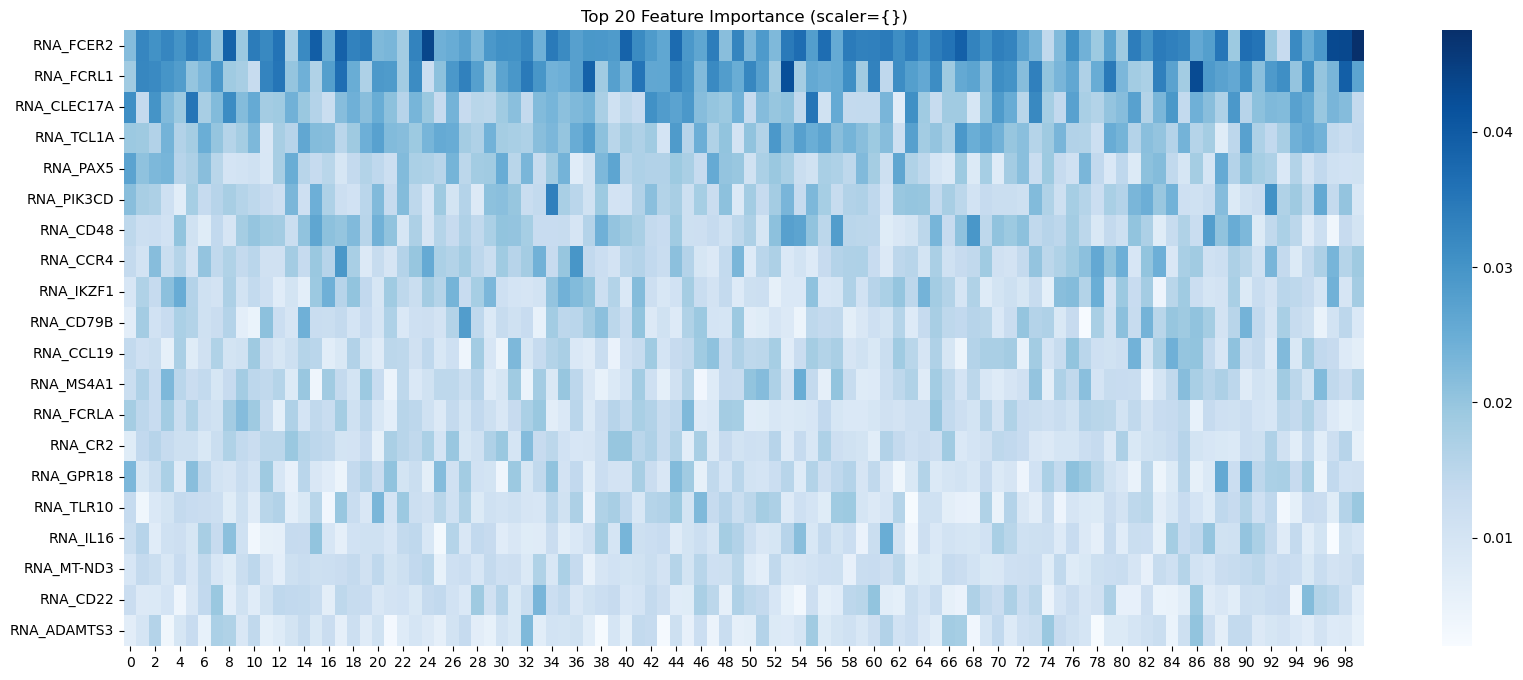

RNA_FCER2       0.02994
RNA_FCRL1      0.026258
RNA_CLEC17A    0.020663
RNA_TCL1A      0.020038
RNA_PAX5       0.016261
RNA_PIK3CD      0.01615
RNA_CD48       0.016053
RNA_CCR4       0.015603
RNA_IKZF1      0.014363
RNA_CD79B      0.013402
RNA_CCL19      0.013309
RNA_MS4A1      0.013209
RNA_FCRLA       0.01263
RNA_CR2        0.012603
RNA_GPR18      0.012539
RNA_TLR10      0.011869
RNA_IL16       0.011617
RNA_MT-ND3     0.011326
RNA_CD22       0.011299
RNA_ADAMTS3    0.010126
dtype: object


In [ ]:
### Feature Importance (Run 100 times)
from model_utils import run_feature_importance
global_importance = run_feature_importance(concat_train, run_seeds=100, concat=True, scaler_dict={}, model=base_model,
                                           save_path=f"/home/data/data_YM313112004/TLS_model/results/{cancer_type}/importance_df/final_model_importance_{random_seed}.csv", plot_top=20)
print(global_importance.head(20))

Feature importance: 100%|██████████| 100/100 [00:32<00:00,  3.07it/s]


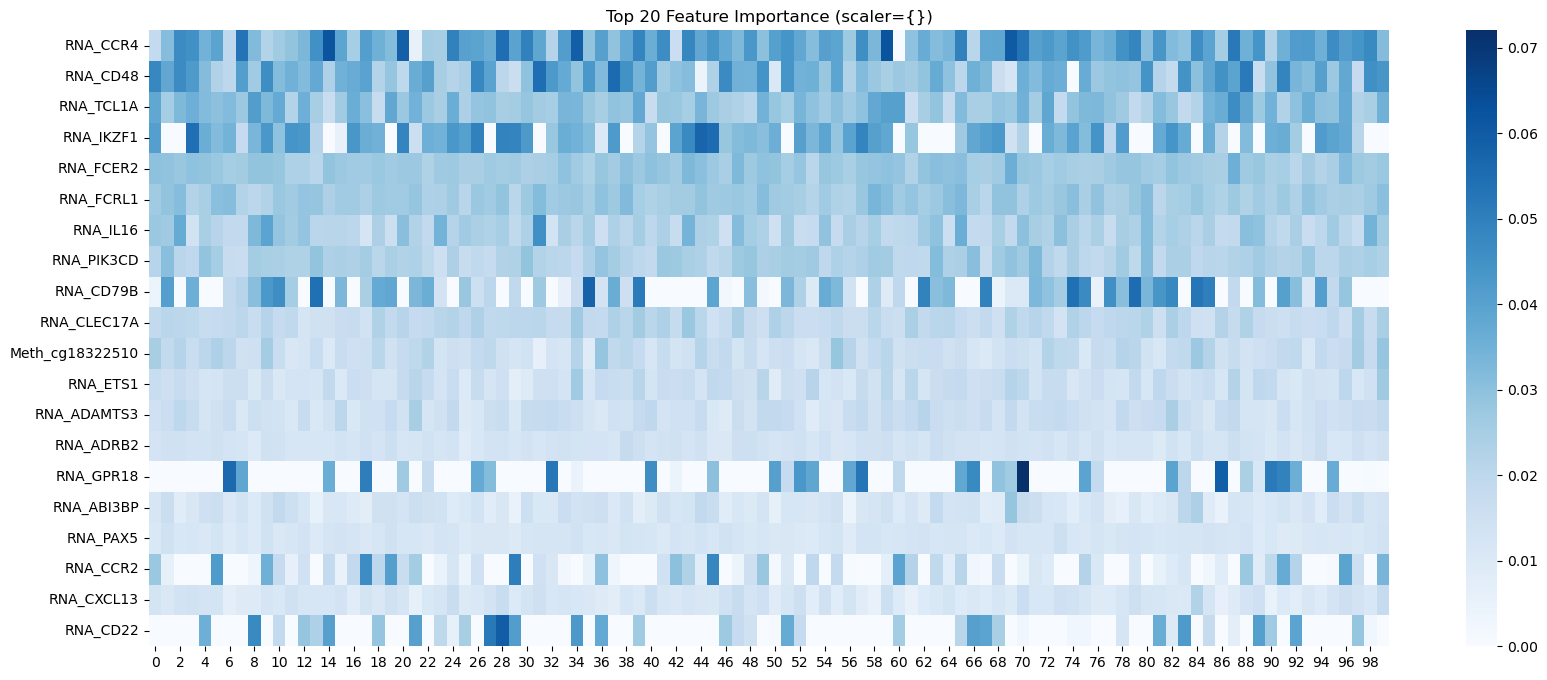

RNA_CCR4           0.037871
RNA_CD48           0.032595
RNA_TCL1A          0.029244
RNA_IKZF1          0.027671
RNA_FCER2          0.027067
RNA_FCRL1          0.026495
RNA_IL16           0.023639
RNA_PIK3CD         0.023312
RNA_CD79B          0.020798
RNA_CLEC17A        0.019291
Meth_cg18322510    0.017049
RNA_ETS1           0.015521
RNA_ADAMTS3        0.015451
RNA_ADRB2          0.013185
RNA_GPR18          0.012824
RNA_ABI3BP         0.012268
RNA_PAX5           0.011815
RNA_CCR2            0.01174
RNA_CXCL13         0.011738
RNA_CD22           0.011107
dtype: object


In [31]:
### Feature Importance (Run 100 times)
from model_utils import run_feature_importance
from xgboost import XGBClassifier
class_weight = sum(concat_train.sample_metadata["TLS"] == 0) / sum(concat_train.sample_metadata["TLS"] == 1)
base_model = XGBClassifier(
                n_estimators=400,
                max_depth=5,
                learning_rate=0.01,
                subsample=0.8,
                colsample_bytree=1,
                reg_lambda=3,
                min_child_weight=5,
                random_state=42,
                scale_pos_weight=class_weight,
                objective="binary:logistic",    # 預設 binary:logistic 就是二分類的 sigmoid，輸出機率
                eval_metric='auc', 
                importance_type="gain",
                n_jobs=10
            )

global_importance = run_feature_importance(concat_train, run_seeds=100, concat=True, scaler_dict={}, model=base_model,
                                           save_path=f"/home/data/data_YM313112004/TLS_model/results/{cancer_type}/importance_df/xgb_test.csv", plot_top=20)
print(global_importance.head(20))

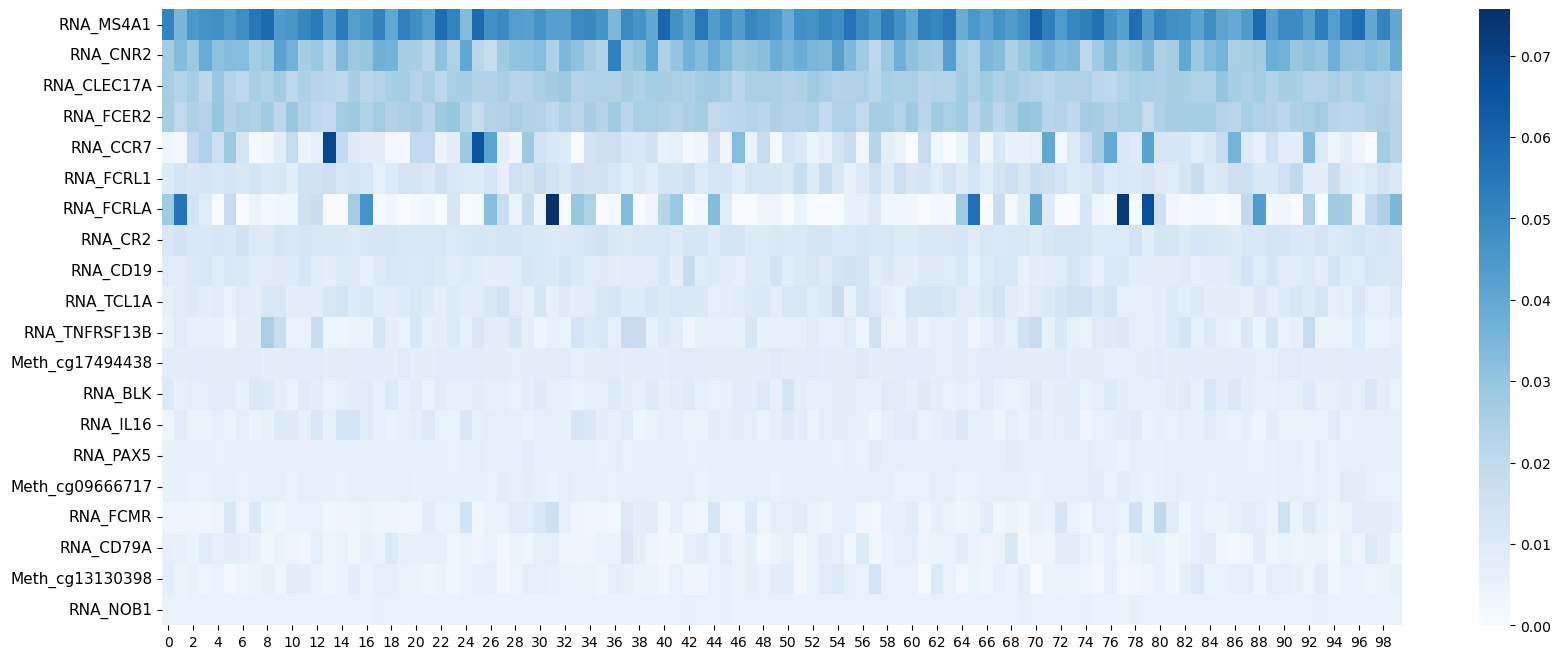

In [43]:
importance_df = pd.read_csv(f"/home/data/data_YM313112004/TLS_model/results/all/importance_df/concat_importance_mrmr_xgb_42.csv", index_col=0)

# 對所有 100 seed 平均
global_importance = importance_df.mean(axis=1).sort_values(ascending=False)

plt.figure(figsize=(20, 8))
sns.heatmap(importance_df.head(20), cmap="Blues")
plt.yticks(fontsize=11)
#plt.title(f"Top 20 Feature Importance")
plt.savefig("/home/data/data_YM313112004/TLS_model/tiff_figure/paper/importance_xgb_pooled.tiff", dpi=300, format='tiff', bbox_inches='tight', pil_kwargs={'compression': 'tiff_lzw'})
plt.show()

Elbow point (Feature top n): 20


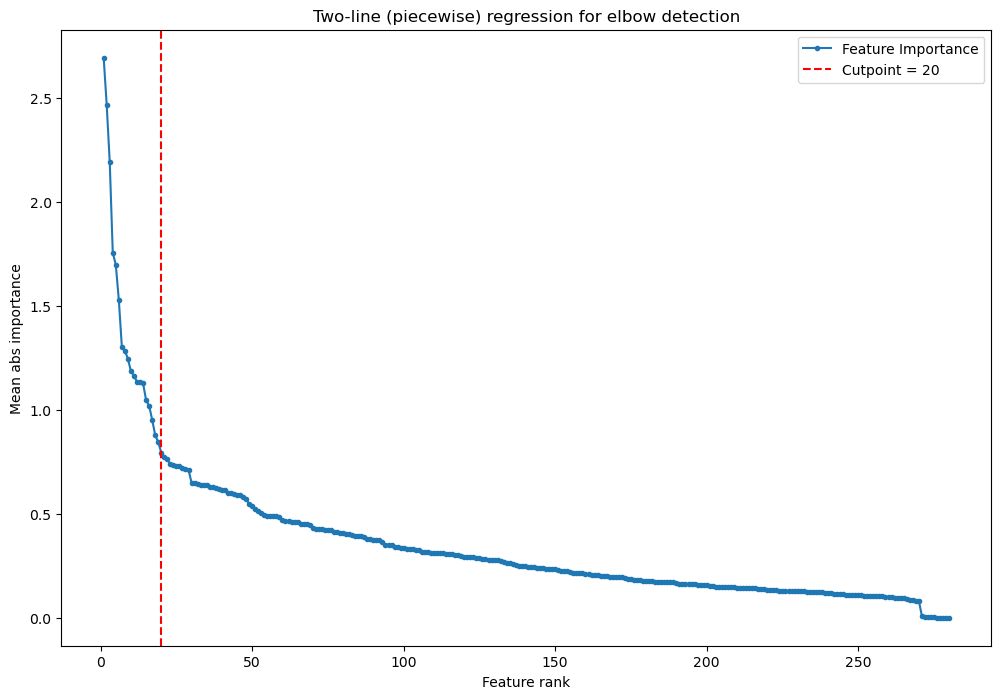

Elbow at: 20


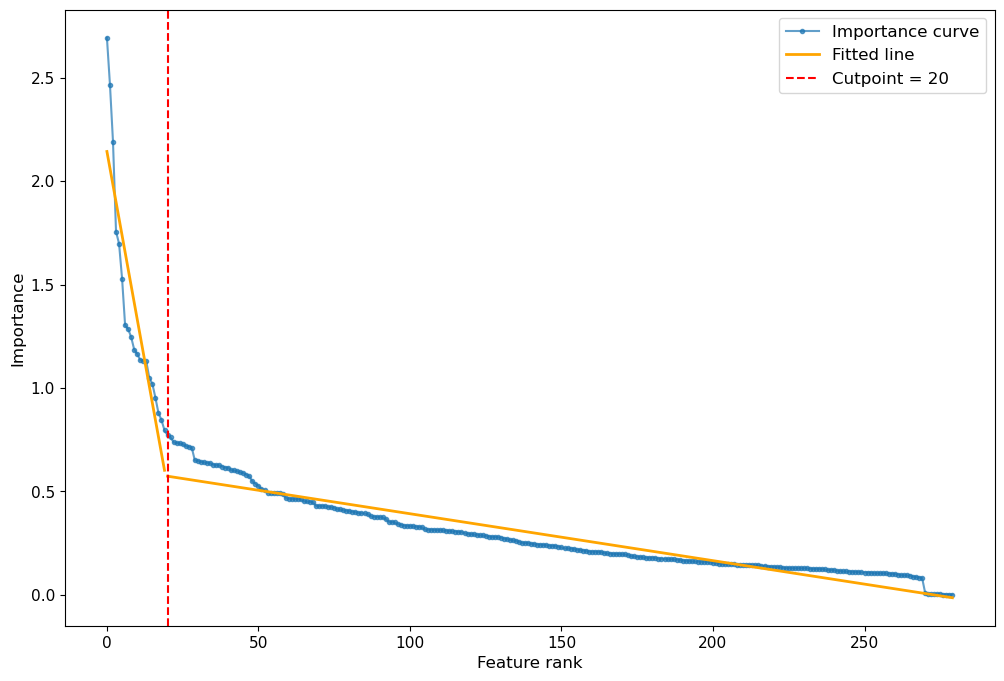

In [52]:
importance_df = pd.read_csv(f"/home/data/data_YM313112004/TLS_model/results/STAD/importance_df/concat_importance_mrmr_catboost_42.csv", index_col=0)
global_importance = importance_df.mean(axis=1).sort_values(ascending=False)

# === 使用你的 importance array === #
global_importance_filter = global_importance[global_importance != 0]
y = global_importance_filter.values          # 你的 SHAP importance 依大小排序 np.array
x = np.arange(len(y))

from model_utils import two_line_elbow
knee_x, rss = two_line_elbow(global_importance)
k = int(knee_x)
print("Elbow at:", k)

# fit 兩條直線（分段線性擬合）
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# 防護：若分段太短則退回常數線
if k <= 1:
    # 全部用單一線
    model_all = LinearRegression().fit(x.reshape(-1,1), y)
    y_fit = model_all.predict(x.reshape(-1,1))
    left_x = x
    left_fit = y_fit
    right_x = np.array([], dtype=int)
    right_fit = np.array([])
else:
    # left: x[:k], right: x[k:]
    x_left = x[:k].reshape(-1,1)
    x_right = x[k:].reshape(-1,1)

    model_left = LinearRegression().fit(x_left, y[:k])
    model_right = LinearRegression().fit(x_right, y[k:])

    left_x = x[:k]
    left_fit = model_left.predict(x_left)

    right_x = x[k:]
    right_fit = model_right.predict(x_right)

# ========== Plot ========= #
plt.figure(figsize=(12,8))
plt.plot(x, y, '.-', label="Importance curve", alpha=0.7)
if len(left_x):
    plt.plot(left_x, left_fit, color='orange', linewidth=2, label='Fitted line')
if len(right_x):
    plt.plot(right_x, right_fit, color='orange', linewidth=2)
plt.axvline(k, color='red', linestyle='--', label=f"Cutpoint = {k}")
plt.legend(fontsize=12)
#plt.title("Elbow Detection with Fitted Lines", fontsize=20)
plt.xticks(fontsize=11)
plt.yticks(fontsize=11)
plt.xlabel("Feature rank", fontsize=12)
plt.ylabel("Importance", fontsize=12)
plt.savefig("/home/data/data_YM313112004/TLS_model/tiff_figure/paper/elbow_catboost_STAD.tiff", dpi=300, format='tiff', bbox_inches='tight', pil_kwargs={'compression': 'tiff_lzw'})
plt.show()

Feature importance:   1%|          | 1/100 [00:01<02:21,  1.43s/it]

Elbow point (Feature top n): 32


Feature importance:   2%|▏         | 2/100 [00:03<02:40,  1.63s/it]

Elbow point (Feature top n): 31


Feature importance:   3%|▎         | 3/100 [00:04<02:27,  1.52s/it]

...

Elbow point (Feature top n): 24


Feature importance:  99%|█████████▉| 99/100 [02:20<00:01,  1.42s/it]

Elbow point (Feature top n): 21


Feature importance: 100%|██████████| 100/100 [02:21<00:00,  1.42s/it]

Elbow point (Feature top n): 30


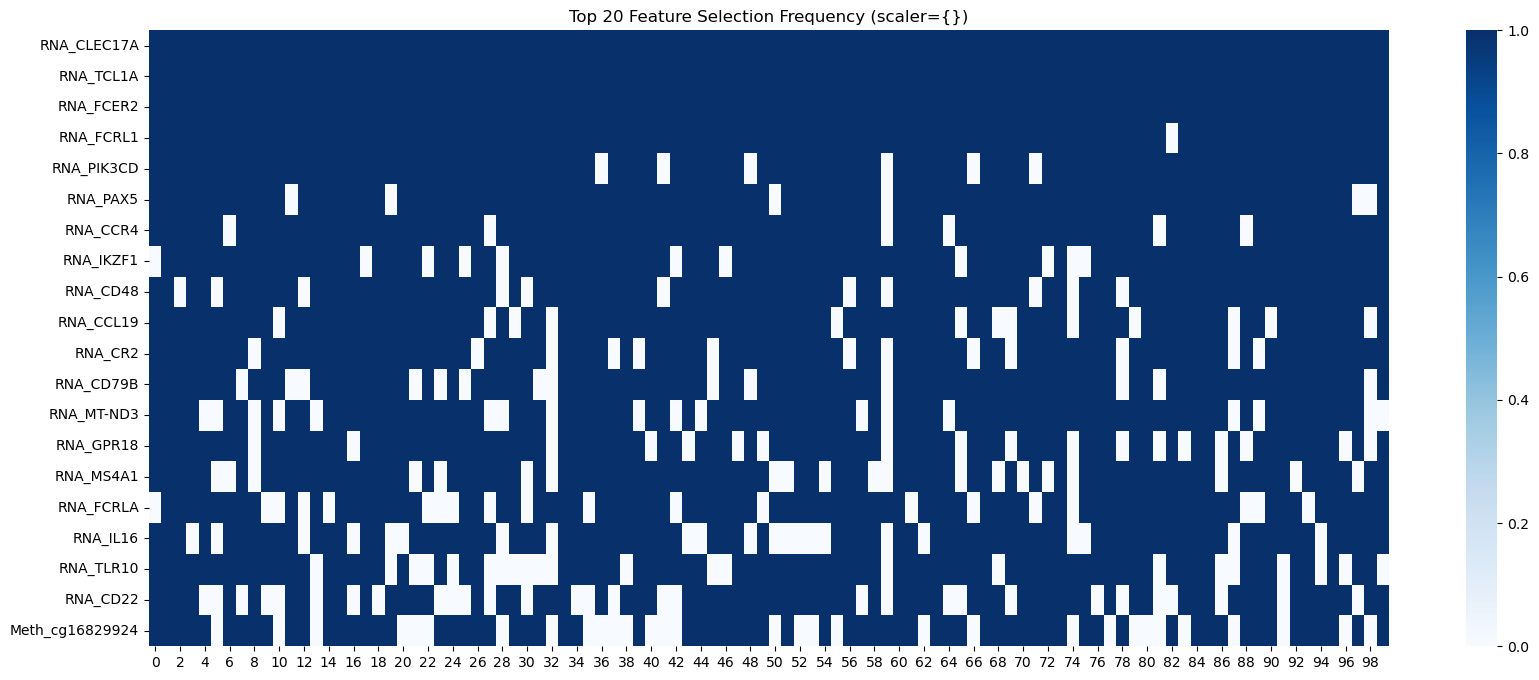

RNA_CLEC17A        1.00
RNA_TCL1A          1.00
RNA_FCER2          1.00
RNA_FCRL1          0.99
RNA_PIK3CD         0.94
RNA_PAX5           0.94
RNA_CCR4           0.94
RNA_IKZF1          0.89
RNA_CD48           0.89
RNA_CCL19          0.87
RNA_CR2            0.87
RNA_CD79B          0.86
RNA_MT-ND3         0.82
RNA_GPR18          0.82
RNA_MS4A1          0.80
RNA_FCRLA          0.80
RNA_IL16           0.78
RNA_TLR10          0.77
RNA_CD22           0.70
Meth_cg16829924    0.69
dtype: float64


In [175]:
### Feature Importance (Run 100 times)
from model_utils import run_feature_importance_freq
from model_utils import build_base_model
base_model = build_base_model("RandomForest", concat_train, random_state=42)
global_importance11 = run_feature_importance_freq(concat_train, run_seeds=100, concat=True, scaler_dict={}, model=base_model, plot_top=20)
print(global_importance11.head(20))

Feature importance: 100%|██████████| 100/100 [01:42<00:00,  1.03s/it]


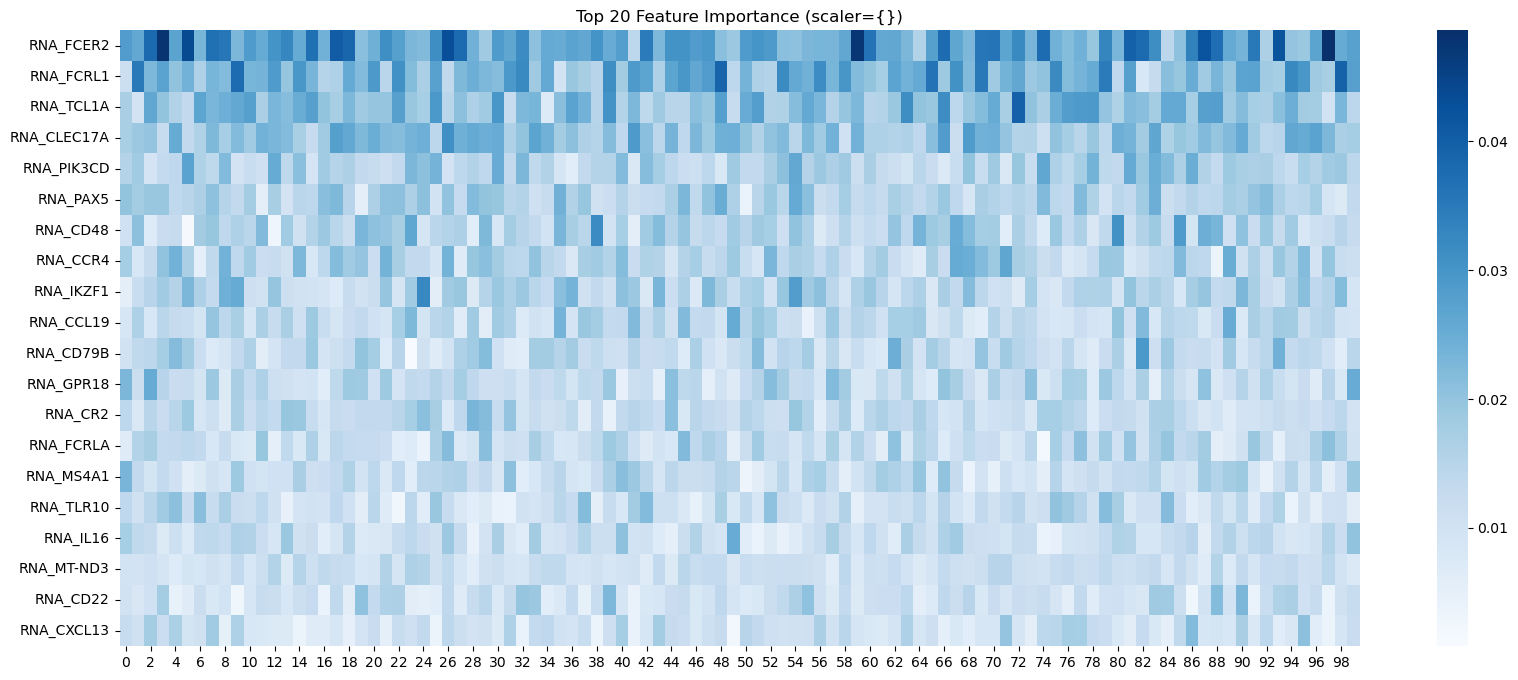

RNA_FCER2      0.028595
RNA_FCRL1      0.023558
RNA_TCL1A       0.02097
RNA_CLEC17A    0.020213
RNA_PIK3CD     0.015967
RNA_PAX5       0.015869
RNA_CD48       0.015578
RNA_CCR4       0.015277
RNA_IKZF1      0.015078
RNA_CCL19      0.013561
RNA_CD79B      0.013192
RNA_GPR18      0.013165
RNA_CR2        0.012975
RNA_FCRLA       0.01253
RNA_MS4A1      0.012203
RNA_TLR10      0.011632
RNA_IL16       0.011603
RNA_MT-ND3     0.011065
RNA_CD22       0.011014
RNA_CXCL13     0.010592
dtype: object


In [176]:
### Feature Importance (Run 100 times)
from model_utils import run_feature_importance
from model_utils import build_base_model
base_model = build_base_model("RandomForest", concat_train, random_state=42)
global_importance = run_feature_importance(concat_train, run_seeds=100, concat=True, scaler_dict={}, model=base_model, plot_top=20)
print(global_importance.head(20))

In [52]:
import pandas as pd
importance_df = pd.read_csv("/home/data/data_YM313112004/TLS_model/results/PAAD/importance_df/concat_importance_mrmr_rf_42.csv", index_col=0)
global_importance = importance_df.mean(axis=1).sort_values(ascending=False)
global_importance = global_importance.astype(object)   # 將資料型別轉換為 object (防止 knee_x 出現小數點)
print(global_importance.head(20))

RNA_FCER2      0.028595
RNA_FCRL1      0.023558
RNA_TCL1A       0.02097
RNA_CLEC17A    0.020213
RNA_PIK3CD     0.015967
RNA_PAX5       0.015869
RNA_CD48       0.015578
RNA_CCR4       0.015277
RNA_IKZF1      0.015078
RNA_CCL19      0.013561
RNA_CD79B      0.013192
RNA_GPR18      0.013165
RNA_CR2        0.012975
RNA_FCRLA       0.01253
RNA_MS4A1      0.012203
RNA_TLR10      0.011632
RNA_IL16       0.011603
RNA_MT-ND3     0.011065
RNA_CD22       0.011014
RNA_CXCL13     0.010592
dtype: object


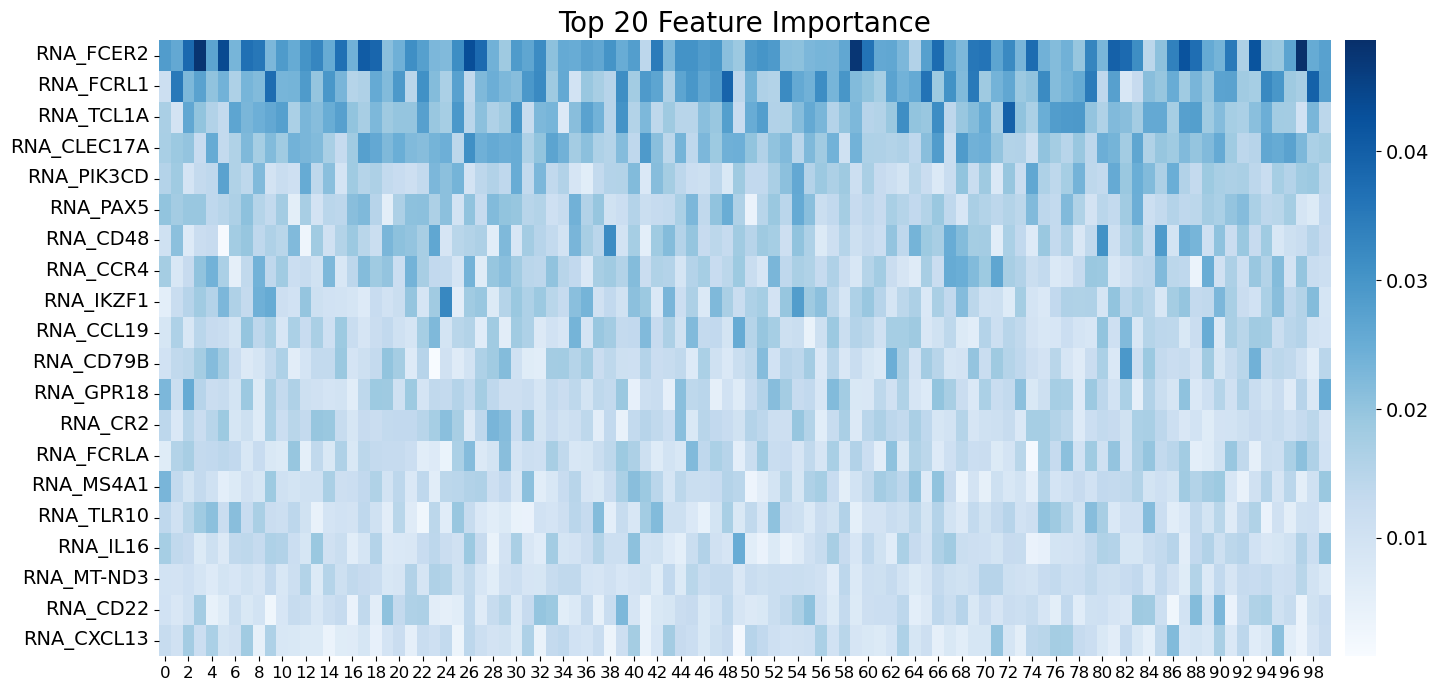

In [ ]:
plt.figure(figsize=(18, 8))
ax = sns.heatmap(importance_df.head(20), cmap="Blues", cbar_kws={"pad": 0.01})
plt.title(f"Top 20 Feature Importance", fontsize=20)
plt.xticks(fontsize=12)
plt.yticks(fontsize=14)
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=14)
plt.savefig('./tiff_figure/Top_20_Feature_Importance.tiff', dpi=300, format='tiff', bbox_inches='tight', pil_kwargs={'compression': 'tiff_lzw'})
plt.show()

Elbow point (Feature top n): 36


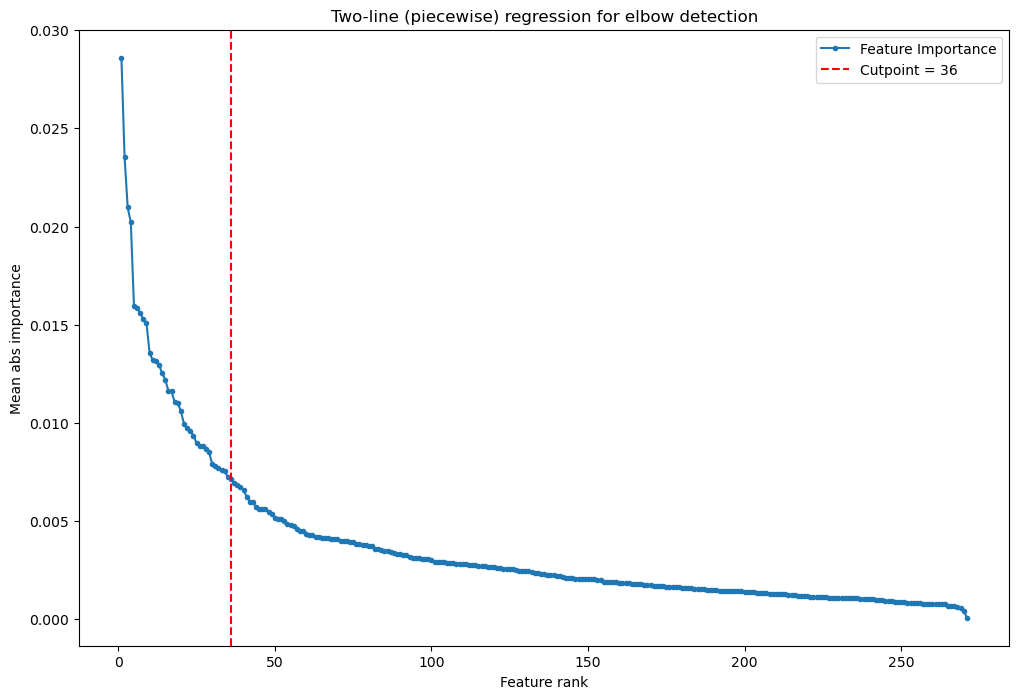

In [39]:
from model_utils import two_line_elbow
knee_x, rss = two_line_elbow(global_importance)

Elbow point (Feature top n): 36


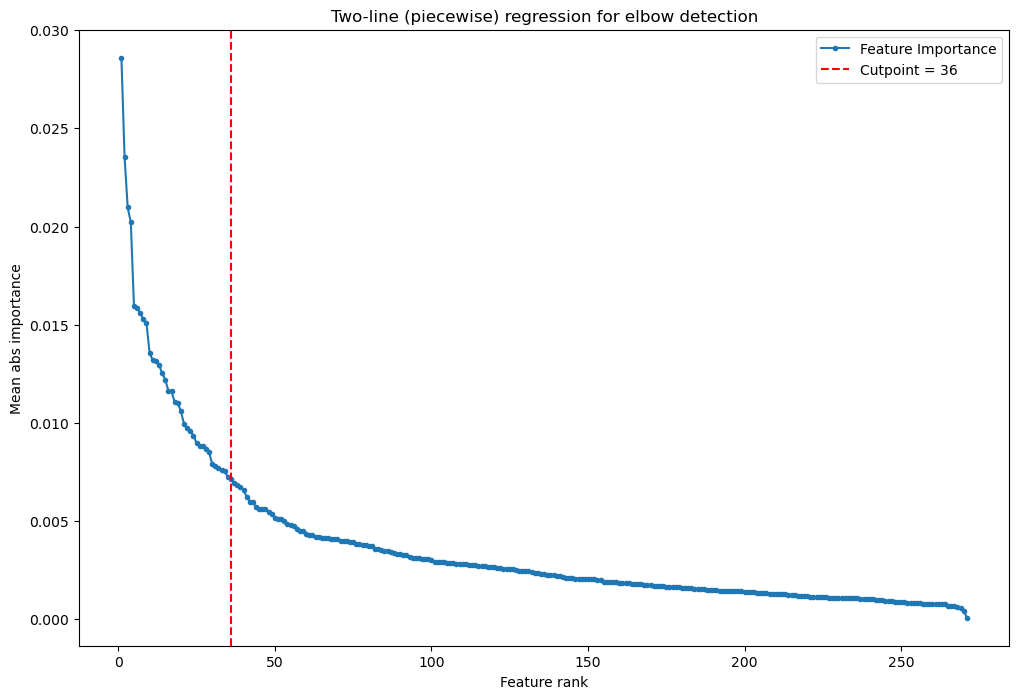

Elbow at: 36


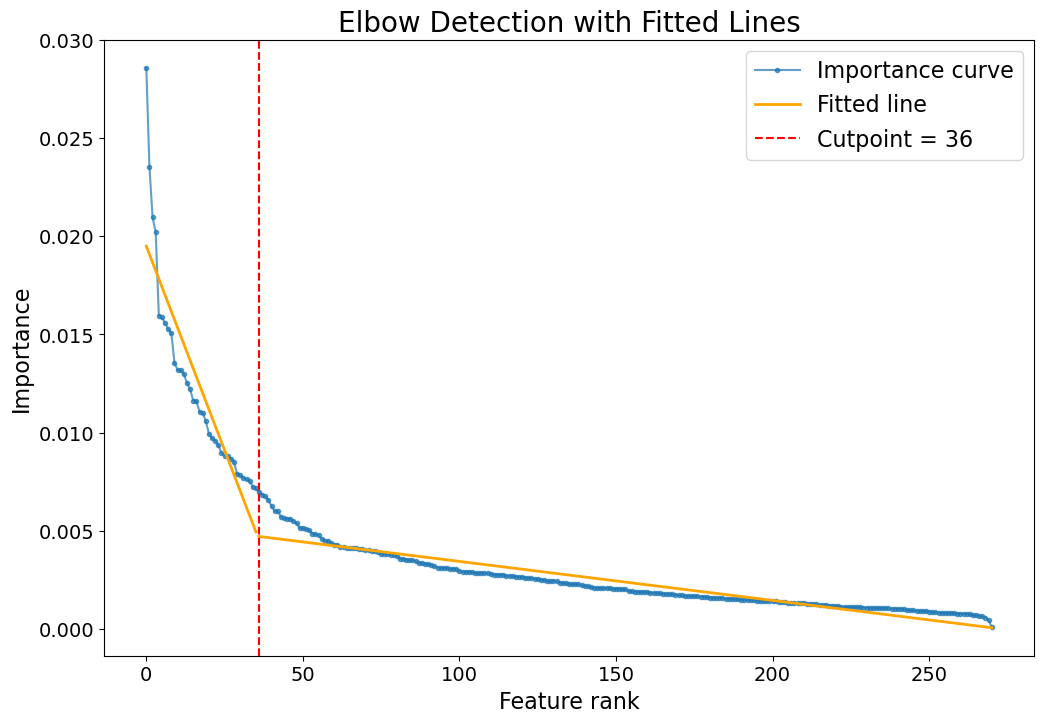

In [ ]:
# === 使用你的 importance array === #
global_importance_filter = global_importance[global_importance != 0]
y = global_importance_filter.values          # 你的 SHAP importance 依大小排序 np.array
x = np.arange(len(y))

from model_utils import two_line_elbow
knee_x, rss = two_line_elbow(global_importance)
k = int(knee_x)
print("Elbow at:", k)

# fit 兩條直線（分段線性擬合）
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# 防護：若分段太短則退回常數線
if k <= 1:
    # 全部用單一線
    model_all = LinearRegression().fit(x.reshape(-1,1), y)
    y_fit = model_all.predict(x.reshape(-1,1))
    left_x = x
    left_fit = y_fit
    right_x = np.array([], dtype=int)
    right_fit = np.array([])
else:
    # left: x[:k], right: x[k:]
    x_left = x[:k].reshape(-1,1)
    x_right = x[k:].reshape(-1,1)

    model_left = LinearRegression().fit(x_left, y[:k])
    model_right = LinearRegression().fit(x_right, y[k:])

    left_x = x[:k]
    left_fit = model_left.predict(x_left)

    right_x = x[k:]
    right_fit = model_right.predict(x_right)

# ========== Plot ========= #
plt.figure(figsize=(12,8))
plt.plot(x, y, '.-', label="Importance curve", alpha=0.7)
if len(left_x):
    plt.plot(left_x, left_fit, color='orange', linewidth=2, label='Fitted line')
if len(right_x):
    plt.plot(right_x, right_fit, color='orange', linewidth=2)
plt.axvline(k, color='red', linestyle='--', label=f"Cutpoint = {k}")
plt.legend(fontsize=16)
plt.title("Elbow Detection with Fitted Lines", fontsize=20)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlabel("Feature rank", fontsize=16)
plt.ylabel("Importance", fontsize=16)
plt.savefig('./tiff_figure/Elbow_Detection.tiff', dpi=300, format='tiff', bbox_inches='tight', pil_kwargs={'compression': 'tiff_lzw'})
plt.show()

In [13]:
top_features = global_importance.head(knee_x).index
#np.save("/home/data/data_YM313112004/TLS_model/results/PAAD/selected_features/top_features_rna.npy", top_features)
print(top_features)

# top_features = np.load("/home/data/data_YM313112004/TLS_model/results/PAAD/selected_features/top_features_concat_mrmr_catboost_42.npy", allow_pickle=True)
# top_features

Index(['Meth_cg08856163', 'Meth_cg22804839', 'Meth_cg13770399',
       'Meth_cg16004738', 'Meth_cg02478828', 'Meth_cg12648201', 'RNA_FCRL5',
       'Meth_cg02654291', 'RNA_CNR2', 'Meth_cg15379633', 'RNA_SCN7A',
       'Meth_cg07773434', 'Meth_cg07300384', 'Meth_cg17890764', 'RNA_RASGRP2',
       'RNA_CD19', 'RNA_FCRL3', 'Meth_cg12967164', 'RNA_FCRL2',
       'Meth_cg03361776', 'RNA_PAX5', 'RNA_FCER2', 'Meth_cg27420224',
       'Meth_cg06178315', 'RNA_FCRL1', 'Meth_cg06795963', 'RNA_EXOC3',
       'RNA_BLK', 'Meth_cg11210878', 'Meth_cg23165164', 'RNA_CCL19',
       'RNA_CD79B', 'RNA_DPT', 'RNA_CR2', 'RNA_MS4A1', 'Meth_cg09676390',
       'RNA_NIBAN3', 'RNA_CIBAR2', 'Meth_cg14584255', 'Meth_cg00206281',
       'Meth_cg23992194', 'RNA_CD79A', 'Meth_cg13466284', 'RNA_STAP1',
       'Meth_cg14582100', 'RNA_TEK', 'Meth_cg08196561', 'RNA_FCRLA',
       'Meth_cg04118119', 'Meth_cg15895782', 'RNA_KANK3', 'RNA_CXCR4',
       'RNA_GTF3C6', 'RNA_TNFRSF13B', 'RNA_CLEC17A', 'RNA_ACKR1',
       'Meth

In [28]:
top_features = np.load("/home/data/data_YM313112004/TLS_model/results/PAAD/selected_features/top_features_concat_mrmr_rf_42.npy", allow_pickle=True)
top_features

array(['RNA_FCER2', 'RNA_FCRL1', 'RNA_CLEC17A', 'RNA_TCL1A', 'RNA_PAX5',
       'RNA_CD48', 'RNA_IKZF1', 'RNA_CCR4', 'RNA_PIK3CD', 'RNA_FCRLA',
       'RNA_CR2', 'RNA_MS4A1', 'RNA_GPR18', 'RNA_CD79B', 'RNA_CCL19',
       'RNA_FCMR', 'RNA_TLR10', 'RNA_CD22', 'RNA_TGFB2', 'RNA_IL16',
       'RNA_CXCL13', 'RNA_SP140', 'RNA_MT-CO3', 'Meth_cg16829924',
       'RNA_CD19', 'RNA_RIPOR2', 'RNA_LTA', 'RNA_TRAF3IP3', 'RNA_TAGAP',
       'RNA_ABI3BP', 'RNA_NLRC3', 'RNA_BLK', 'RNA_CCR7', 'RNA_SLCO3A1',
       'RNA_SIT1', 'RNA_SOX15', 'RNA_NOMO2', 'Meth_cg18322510',
       'RNA_CCR2', 'RNA_VPREB3'], dtype=object)

In [29]:
from model_utils import evaluate_model
from catboost import CatBoostClassifier
class_weight = sum(PAAD_train.sample_metadata["TLS"] == 0) / sum(PAAD_train.sample_metadata["TLS"] == 1)
model = CatBoostClassifier(random_seed=42, class_weights=[1, class_weight], verbose=0)  
report, y_train, y_pred_prob, y_test, y_test_pred_prob, best_cutoff = evaluate_model(PAAD_train, PAAD_test, top_features=top_features, concat=True, scaler_dict={}, model=model)
print(report)

Selected top 40 features
Best cutoff in AUROC: 0.776296280373981
Train | F1-score: 1.000 | Accuracy: 1.000 | AUC: 1.000 | AUPRC: 1.000
Test  | F1-score: 0.545 | Accuracy: 0.714 | AUC: 0.832 | AUPRC: 0.784
              precision    recall  f1-score   support

TLS-negative      0.731     0.864     0.792        22
TLS-positive      0.667     0.462     0.545        13

    accuracy                          0.714        35
   macro avg      0.699     0.663     0.669        35
weighted avg      0.707     0.714     0.700        35



In [ ]:
from model_utils import evaluate_model
from catboost import CatBoostClassifier
class_weight = sum(concat_train.sample_metadata["TLS"] == 0) / sum(concat_train.sample_metadata["TLS"] == 1)
model = CatBoostClassifier(random_seed=42, class_weights=[1, class_weight], verbose=0)  
report, y_train, y_pred_prob, y_test, y_test_pred_prob, best_cutoff = evaluate_model(concat_train, concat_test, top_features=top_features, concat=True, scaler_dict={}, model=model)
print(report)

Selected top 21 features
Best cutoff in AUROC: 0.8284433549394754
Train | F1-score: 1.000 | Accuracy: 1.000 | AUC: 1.000 | AUPRC: 1.000
Test  | F1-score: 0.571 | Accuracy: 0.743 | AUC: 0.850 | AUPRC: 0.797
              precision    recall  f1-score   support

TLS-negative      0.741     0.909     0.816        22
TLS-positive      0.750     0.462     0.571        13

    accuracy                          0.743        35
   macro avg      0.745     0.685     0.694        35
weighted avg      0.744     0.743     0.725        35



In [37]:
y_pred = (y_pred_prob >= best_cutoff).astype(int)
report = classification_report(y_train, y_pred, target_names=['TLS-negative', 'TLS-positive'], digits=3)
print(report)

              precision    recall  f1-score   support

TLS-negative      1.000     1.000     1.000        88
TLS-positive      1.000     1.000     1.000        49

    accuracy                          1.000       137
   macro avg      1.000     1.000     1.000       137
weighted avg      1.000     1.000     1.000       137



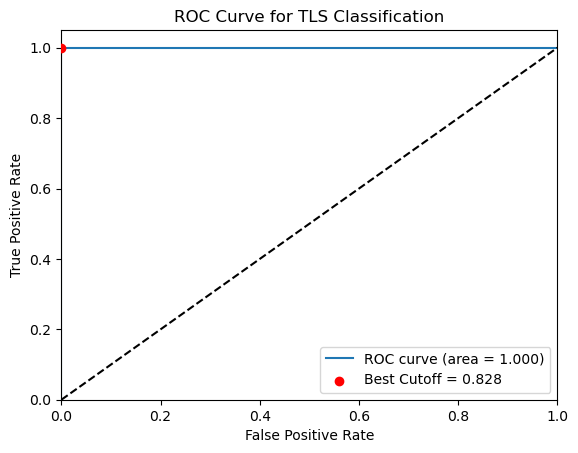

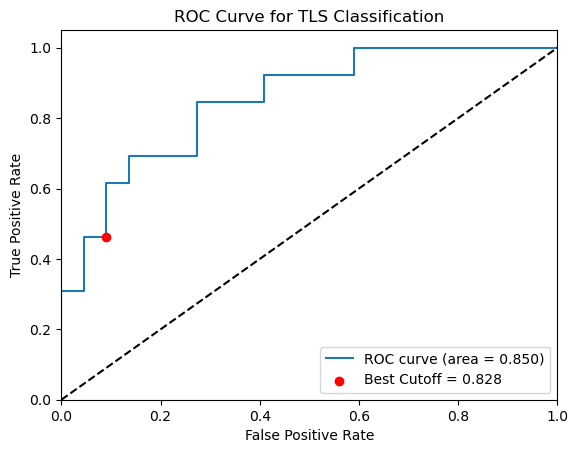

In [35]:
# Calculate ROC curves
from sklearn.metrics import roc_curve, auc
fpr, tpr, roc_thresholds = roc_curve(y_train, y_pred_prob)
roc_auc = auc(fpr, tpr)
idx_roc = np.abs(roc_thresholds - best_cutoff).argmin()
best_fpr, best_tpr = fpr[idx_roc], tpr[idx_roc]

# Plot the ROC curve
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = %0.3f)' % roc_auc, drawstyle='steps-post')
plt.plot([0, 1], [0, 1], 'k--')
plt.scatter(best_fpr, best_tpr, color='red', label=f'Best Cutoff = {best_cutoff:.3f}', zorder=5)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for TLS Classification')
plt.legend()
plt.savefig('ROC_Curve_Test.png', dpi=300)
plt.show()


# Calculate ROC curves
fpr, tpr, roc_thresholds = roc_curve(y_test, y_test_pred_prob)
roc_auc = auc(fpr, tpr)
idx_roc = np.abs(roc_thresholds - best_cutoff).argmin()
best_fpr, best_tpr = fpr[idx_roc], tpr[idx_roc]

# Plot the ROC curve
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = %0.3f)' % roc_auc, drawstyle='steps-post')
plt.plot([0, 1], [0, 1], 'k--')
plt.scatter(best_fpr, best_tpr, color='red', label=f'Best Cutoff = {best_cutoff:.3f}', zorder=5)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for TLS Classification')
plt.legend()
plt.savefig('ROC_Curve_Test.png', dpi=300)
plt.show()

In [34]:
roc_curve(y_train, y_pred_prob)

(array([0., 0., 0., 1.]),
 array([0.        , 0.02040816, 1.        , 1.        ]),
 array([       inf, 0.99211538, 0.82844335, 0.01621066]))

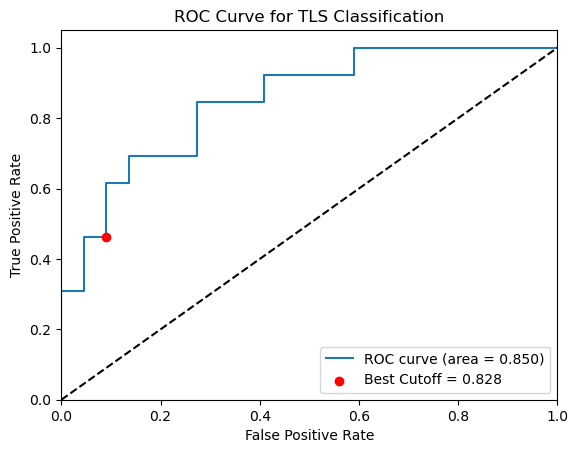

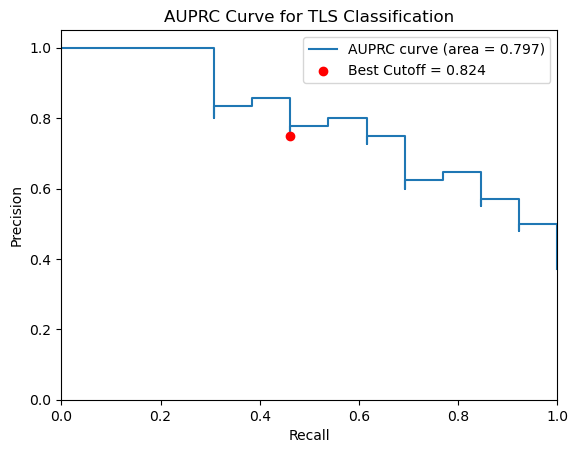

In [ ]:
# Calculate ROC curves
from sklearn.metrics import roc_curve, precision_recall_curve, auc, average_precision_score
fpr, tpr, roc_thresholds = roc_curve(y_test, y_test_pred_prob)
roc_auc = auc(fpr, tpr)
idx_roc = np.abs(roc_thresholds - best_cutoff).argmin()
best_fpr, best_tpr = fpr[idx_roc], tpr[idx_roc]

# Calculate PR curves: precision_recall_curve returns len(thresholds) = len(precision)-1
precision, recall, pr_thresholds = precision_recall_curve(y_test, y_test_pred_prob)
pr_auc = average_precision_score(y_test, y_test_pred_prob)
idx_pr = np.abs(pr_thresholds - best_cutoff).argmin()
best_recall = recall[idx_pr + 1]
best_precision = precision[idx_pr + 1]
best_pr_threshold = pr_thresholds[idx_pr]

# Plot the ROC curve
plt.figure()
plt.plot(fpr, tpr, label='ROC curve (area = %0.3f)' % roc_auc, drawstyle='steps-post')
plt.plot([0, 1], [0, 1], 'k--')
plt.scatter(best_fpr, best_tpr, color='red', label=f'Best Cutoff = {best_cutoff:.3f}', zorder=5)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for TLS Classification')
plt.legend()
plt.savefig('ROC_Curve_Test.png', dpi=300)
plt.show()

# Plot the AUPRC curve
plt.figure()  
plt.plot(recall, precision, label='AUPRC curve (area = %0.3f)' % pr_auc, drawstyle='steps-post')
plt.scatter(best_recall, best_precision, color='red', label=f'Best Cutoff = {best_pr_threshold:.3f}', zorder=5)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('AUPRC Curve for TLS Classification')
plt.legend()
plt.savefig('AUPRC_Curve_Test.png', dpi=300)
plt.show()

In [16]:
common_features = ['RNA_CLEC17A', 'RNA_CR2', 'RNA_TCL1A', 'RNA_PAX5']
from model_utils import evaluate_model
from catboost import CatBoostClassifier
class_weight = sum(concat_train.sample_metadata["TLS"] == 0) / sum(concat_train.sample_metadata["TLS"] == 1)
model = CatBoostClassifier(random_seed=42, class_weights=[1, class_weight], verbose=0)  
report, y_train, y_pred_prob, y_test, y_test_pred_prob, best_cutoff = evaluate_model(PAAD_train, PAAD_test, top_features=common_features, concat=True, scaler_dict={}, model=model)
print(report)

Selected top 4 features
Best cutoff in AUROC: 0.71678656153527
Train | F1-score: 0.948 | Accuracy: 0.964 | AUC: 0.990 | AUPRC: 0.984
Test  | F1-score: 0.714 | Accuracy: 0.771 | AUC: 0.846 | AUPRC: 0.732
              precision    recall  f1-score   support

TLS-negative       0.85      0.77      0.81        22
TLS-positive       0.67      0.77      0.71        13

    accuracy                           0.77        35
   macro avg       0.76      0.77      0.76        35
weighted avg       0.78      0.77      0.77        35



### Independent Dataset

In [24]:
top_features = np.load(f"/home/data/data_YM313112004/TLS_model/results/PAAD/selected_features/top_features_concat_mrmr_catboost_42.npy", allow_pickle=True)
top_features

array(['CNV_138', 'RNA_FCER2', 'RNA_MT-CO3', 'RNA_PAX5', 'RNA_FCRL1',
       'RNA_TGFB2', 'Meth_cg16829924', 'RNA_ADGRE2', 'RNA_CTSV',
       'RNA_CLEC17A', 'Meth_cg12626589', 'RNA_CR2', 'RNA_SLCO3A1',
       'Meth_cg03875996', 'Meth_cg14947478', 'RNA_TCL1A', 'RNA_NOMO2',
       'RNA_ABI3BP', 'Meth_cg12163490', 'RNA_SOX15', 'Meth_cg15244874'],
      dtype=object)

In [16]:
from model_utils import concat_omics
CHOL_concat = concat_omics([CHOL_rna, CHOL_meth, CHOL_mut, CHOL_cnv_cluster], keys=["RNA", "Meth", "Mutation", "CNV"], axis=0)
CHOL_concat[CHOL_concat.index.isin(top_features)]

sample,TCGA-W5-AA2T-01A,TCGA-W5-AA2X-01A,TCGA-ZU-A8S4-01A,TCGA-W5-AA2G-01A,TCGA-W5-AA39-01A,TCGA-ZH-A8Y1-01A,TCGA-ZH-A8Y8-01A,TCGA-3X-AAV9-01A,TCGA-W5-AA34-01A,TCGA-4G-AAZT-01A,...,TCGA-W5-AA36-01A,TCGA-W5-AA2Z-01A,TCGA-W5-AA33-01A,TCGA-W5-AA2O-01A,TCGA-YR-A95A-01A,TCGA-W5-AA2U-01A,TCGA-W5-AA2I-01A,TCGA-W6-AA0S-01A,TCGA-W5-AA31-01A,TCGA-WD-A7RX-01A
RNA_ABI3BP,0.383939,0.828469,5.096300,1.360645,0.585443,1.574877,3.736194,3.078610,1.633292,1.094168,...,0.111966,2.161307,3.767125,0.419647,3.871538,2.259122,0.152508,2.311561,0.917088,2.574949
RNA_ADAMTS3,0.197865,0.152508,0.876409,0.493237,0.102994,0.849759,0.685626,1.202010,0.086920,0.163499,...,0.146655,0.798507,0.831229,0.121811,0.235359,0.590626,0.043204,1.279412,0.655077,0.407951
RNA_ADRB2,0.328607,0.978415,1.901301,1.662570,3.055491,0.515612,2.038542,2.599675,0.554540,0.751464,...,0.456911,0.779974,2.480679,0.912343,1.177535,1.169155,0.179129,0.480162,1.285521,2.130964
RNA_BLK,0.025029,0.067363,0.214622,0.186501,0.000000,0.000000,3.221630,1.441643,0.042084,0.169540,...,0.039560,0.024745,2.147404,0.150820,0.096397,0.351628,0.015498,0.148088,0.072174,1.990991
RNA_CCL19,0.000000,1.210389,1.848277,5.953517,0.487898,1.343806,8.906879,8.207331,1.088549,6.520042,...,0.693677,4.172143,9.066568,3.687688,4.766426,6.331775,0.813196,4.613485,3.460887,10.059713
RNA_CCR2,0.355467,0.304277,2.732812,1.600793,0.176067,0.768756,1.608383,2.828185,0.558268,1.202700,...,0.877116,1.399226,3.049666,0.158337,0.607011,1.834549,0.093019,0.734222,2.059009,2.412944
RNA_CCR4,0.155102,0.036749,1.008128,1.065848,0.000000,0.747516,2.000144,2.220670,0.841329,0.138945,...,0.154065,0.478195,3.462641,0.205518,0.313362,1.424008,0.049910,1.976070,0.662114,2.136060
RNA_CD19,0.089498,0.368936,0.371169,0.356595,0.255078,0.111833,4.629281,2.630662,0.183074,0.227864,...,0.172744,0.288890,2.689075,0.080794,0.000000,0.899562,0.000000,0.260267,0.409798,3.842838
RNA_CD22,4.374511,0.383165,0.761030,3.642193,0.265197,2.253899,5.123985,2.799937,2.157335,0.812539,...,1.422825,3.303152,3.580447,4.561760,2.475085,3.157836,0.815166,2.607105,1.160146,3.739070
RNA_CD48,0.560519,0.338111,2.731357,2.448452,0.089091,1.260146,4.070870,3.734525,1.169220,1.692249,...,1.174534,1.359409,3.520473,1.014498,1.255682,1.900529,0.652877,1.601982,1.949161,3.781076


In [26]:
from model_utils import evaluate_model
from catboost import CatBoostClassifier
class_weight = sum(concat_train.sample_metadata["TLS"] == 0) / sum(concat_train.sample_metadata["TLS"] == 1)
model = CatBoostClassifier(random_seed=42, class_weights=[1, class_weight], verbose=0)  
f1_train, acc_train, auc_train, f1_test, acc_test, auc_test = evaluate_model(concat_train, CHOL_concat, top_features=top_features, concat=True, scaler_dict={}, model=model)
print(f"Train | F1-score: {f1_train:.3f} | Accuracy: {acc_train:.3f} | AUC: {auc_train:.3f}")
print(f"Test  | F1-score: {f1_test:.3f} | Accuracy: {acc_test:.3f} | AUC: {auc_test:.3f}")

/home/data/data_YM313112004/TLS_model/utils/model_utils.py:716: UserWarning: [WARNING] Omics 'Mutation' has no overlapping features between train and test. Skipped.
  warnings.warn(f"[WARNING] Omics '{omics}' has no overlapping features between train and test. Skipped.", UserWarning)
/home/data/data_YM313112004/TLS_model/utils/model_utils.py:754: UserWarning: 下列 top_features 在 test_table 中找不到，將被忽略：['Meth_cg16829924']
  warnings.warn(f"下列 top_features 在 test_table 中找不到，將被忽略：{missing_in_test}", UserWarning)


Selected top 20 features
Best cutoff in AUROC: 0.8202444220570507
Train | F1-score: 1.000 | Accuracy: 1.000 | AUC: 1.000
Test  | F1-score: 0.600 | Accuracy: 0.882 | AUC: 0.976


In [27]:
common_features = ['RNA_CLEC17A', 'RNA_CR2', 'RNA_TCL1A', 'RNA_PAX5']
from model_utils import evaluate_model
from catboost import CatBoostClassifier
class_weight = sum(concat_train.sample_metadata["TLS"] == 0) / sum(concat_train.sample_metadata["TLS"] == 1)
model = CatBoostClassifier(random_seed=42, class_weights=[1, class_weight], verbose=0)  
f1_train, acc_train, auc_train, f1_test, acc_test, auc_test = evaluate_model(concat_train, CHOL_concat, top_features=common_features, concat=True, scaler_dict={}, model=model)
print(f"Train | F1-score: {f1_train:.3f} | Accuracy: {acc_train:.3f} | AUC: {auc_train:.3f}")
print(f"Test  | F1-score: {f1_test:.3f} | Accuracy: {acc_test:.3f} | AUC: {auc_test:.3f}")

/home/data/data_YM313112004/TLS_model/utils/model_utils.py:716: UserWarning: [WARNING] Omics 'Mutation' has no overlapping features between train and test. Skipped.
  warnings.warn(f"[WARNING] Omics '{omics}' has no overlapping features between train and test. Skipped.", UserWarning)


Selected top 4 features
Best cutoff in AUROC: 0.71678656153527
Train | F1-score: 0.948 | Accuracy: 0.964 | AUC: 0.990
Test  | F1-score: 0.727 | Accuracy: 0.912 | AUC: 0.982


In [17]:
from model_utils import concat_omics
STAD_concat = concat_omics([STAD_rna, STAD_meth, STAD_mut, STAD_cnv_cluster], keys=["RNA", "Meth", "Mutation", "CNV"], axis=0)
STAD_concat[STAD_concat.index.isin(top_features)]

sample,TCGA-BR-8678-01A,TCGA-BR-8077-01A,TCGA-CG-5732-01A,TCGA-HU-A4HB-01A,TCGA-VQ-A8DT-01A,TCGA-HU-8249-01A,TCGA-BR-7957-01A,TCGA-BR-A4IZ-01A,TCGA-BR-8366-01A,TCGA-BR-A453-01A,...,TCGA-HU-A4GD-01A,TCGA-VQ-A91A-01A,TCGA-VQ-A94P-01A,TCGA-HU-8608-01A,TCGA-BR-A4J1-01A,TCGA-D7-A6EY-01A,TCGA-VQ-A928-01A,TCGA-FP-7916-01A,TCGA-D7-8570-01A,TCGA-F1-6177-01A
RNA_ABI3BP,2.001838,2.376985,2.551344,3.967630,1.001586,1.166073,5.640245,6.750316,3.415123,5.682475,...,1.254171,1.786345,5.890082,2.262974,2.231678,4.048698,2.090515,4.275618,3.515725,0.369606
RNA_ADAMTS3,0.353775,0.327112,0.203640,0.469573,0.248656,0.668573,1.764431,3.045653,0.500802,0.638862,...,0.308943,2.029842,1.142609,0.420725,0.346191,0.443501,0.990447,0.510759,0.286999,0.280362
RNA_ADRB2,0.596554,0.786513,2.812293,2.376902,0.765789,0.445833,2.766638,2.832607,1.916018,2.924803,...,0.574344,1.333023,4.325566,1.504112,0.539134,2.181293,0.940054,2.162500,1.380452,0.169155
RNA_BLK,0.232906,0.635801,2.623399,4.475461,1.469157,0.418892,0.848398,1.530920,1.907506,0.557876,...,0.423524,0.378179,1.175620,0.847115,0.058386,3.096532,0.382169,1.838185,1.184280,0.085833
RNA_CCL19,1.585251,4.592451,5.247366,7.519633,0.743300,3.226801,5.244446,6.247607,7.510457,6.154838,...,2.325127,2.653587,6.180038,3.699541,1.817009,7.480156,3.022297,6.675422,4.948554,0.662844
RNA_CCR2,1.325444,0.824971,1.813894,1.905004,0.377735,0.511974,1.789896,2.377512,3.070338,0.902884,...,0.119423,1.924138,2.247138,4.909778,0.504570,2.212569,0.681674,3.051964,2.471135,0.233397
RNA_CCR4,1.169668,1.718658,2.264176,3.303445,0.764771,1.663982,2.272889,2.751014,2.864137,1.542753,...,1.281965,1.017281,1.762221,4.231455,0.461424,3.598782,1.284040,3.318418,3.251628,0.761626
RNA_CD19,0.491494,2.092783,3.368307,5.478341,0.598746,1.135141,0.689746,1.802855,3.053772,0.890330,...,2.648120,1.127765,1.508530,3.140893,1.600079,4.194371,0.819423,3.051668,2.553188,0.418244
RNA_CD22,0.681584,0.970780,2.878353,6.084198,0.493237,1.459484,1.581014,3.318519,3.385887,1.436961,...,1.886862,0.677350,1.762987,2.239765,0.234747,4.960831,1.016995,2.373593,1.949386,0.314639
RNA_CD48,1.417974,2.761264,3.707492,4.690791,1.189603,2.430553,2.373091,3.416961,4.393636,2.746098,...,0.965618,2.374789,3.353606,3.896030,1.003098,4.096144,1.666438,3.711715,3.734547,2.055022


In [29]:
from model_utils import evaluate_model
from catboost import CatBoostClassifier
class_weight = sum(concat_train.sample_metadata["TLS"] == 0) / sum(concat_train.sample_metadata["TLS"] == 1)
model = CatBoostClassifier(random_seed=42, class_weights=[1, class_weight], verbose=0) 
f1_train, acc_train, auc_train, f1_test, acc_test, auc_test = evaluate_model(concat_train, STAD_concat, top_features=top_features, concat=True, scaler_dict={}, model=model)
print(f"Train | F1-score: {f1_train:.3f} | Accuracy: {acc_train:.3f} | AUC: {auc_train:.3f}")
print(f"Test  | F1-score: {f1_test:.3f} | Accuracy: {acc_test:.3f} | AUC: {auc_test:.3f}")

Selected top 21 features
Best cutoff in AUROC: 0.8284433549394754
Train | F1-score: 1.000 | Accuracy: 1.000 | AUC: 1.000
Test  | F1-score: 0.384 | Accuracy: 0.693 | AUC: 0.770


In [30]:
common_features = ['RNA_CLEC17A', 'RNA_CR2', 'RNA_TCL1A', 'RNA_PAX5']
from model_utils import evaluate_model
from catboost import CatBoostClassifier
class_weight = sum(concat_train.sample_metadata["TLS"] == 0) / sum(concat_train.sample_metadata["TLS"] == 1)
model = CatBoostClassifier(random_seed=42, class_weights=[1, class_weight], verbose=0) 
f1_train, acc_train, auc_train, f1_test, acc_test, auc_test = evaluate_model(concat_train, STAD_concat, top_features=common_features, concat=True, scaler_dict={}, model=model)
print(f"Train | F1-score: {f1_train:.3f} | Accuracy: {acc_train:.3f} | AUC: {auc_train:.3f}")
print(f"Test  | F1-score: {f1_test:.3f} | Accuracy: {acc_test:.3f} | AUC: {auc_test:.3f}")

Selected top 4 features
Best cutoff in AUROC: 0.71678656153527
Train | F1-score: 0.948 | Accuracy: 0.964 | AUC: 0.990
Test  | F1-score: 0.634 | Accuracy: 0.730 | AUC: 0.781


### Common Features in Different Cancers

In [19]:
# Common TLS signatures performance
top_features_CHOL = np.load(f"/home/data/data_YM313112004/TLS_model/results/CHOL/selected_features/TLS_signatures_{random_seed}.npy", allow_pickle=True)
top_features_PAAD = np.load(f"/home/data/data_YM313112004/TLS_model/results/PAAD/selected_features/TLS_signatures_{random_seed}.npy", allow_pickle=True)
top_features_STAD = np.load(f"/home/data/data_YM313112004/TLS_model/results/STAD/selected_features/TLS_signatures_{random_seed}.npy", allow_pickle=True)
common_features = list(set(top_features_CHOL) & set(top_features_PAAD) | set(top_features_CHOL) & set(top_features_STAD) | set(top_features_PAAD) & set(top_features_STAD))
print(f"Common features: {common_features}")

Common features: ['RNA_CLEC17A', 'RNA_FCRL1', 'RNA_TCL1A', 'RNA_MS4A1', 'RNA_PAX5', 'RNA_CR2', 'RNA_CNR2', 'RNA_FCRL2']


In [23]:
#common_features = ['RNA_FCER2', 'RNA_FCRL1', 'RNA_BLK', 'RNA_CNR2', 'RNA_MS4A1', 'RNA_FCRLA', 'RNA_CR2', 'RNA_CD79B', 'RNA_CCL19', 'RNA_CD19']
#common_features = ['RNA_CLEC17A', 'RNA_CR2', 'RNA_TCL1A', 'RNA_PAX5']
#common_features = ['RNA_CR2', 'RNA_PAX5']
from model_utils import evaluate_model
from model_utils import build_base_model
base_model = build_base_model("RandomForest", PAAD_train, random_state=42)
report, y_train, y_pred_prob, y_test, y_test_pred_prob, best_cutoff = evaluate_model(PAAD_train, PAAD_test, top_features=common_features, concat=True, model=base_model)
print(report)

Selected top 8 features
Best cutoff in AUROC: 0.5903692741144198
Train | F1-score: 0.835 | Accuracy: 0.876 | AUC: 0.946 | AUPRC: 0.910
Test  | F1-score: 0.714 | Accuracy: 0.771 | AUC: 0.846 | AUPRC: 0.761
              precision    recall  f1-score   support

TLS-negative      0.850     0.773     0.810        22
TLS-positive      0.667     0.769     0.714        13

    accuracy                          0.771        35
   macro avg      0.758     0.771     0.762        35
weighted avg      0.782     0.771     0.774        35



In [25]:
from model_utils import concat_omics
CHOL_concat = concat_omics([CHOL_rna, CHOL_meth, CHOL_mut, CHOL_cnv_cluster], keys=["RNA", "Meth", "Mutation", "CNV"], axis=0)
CHOL_concat[CHOL_concat.index.isin(common_features)]

sample,TCGA-W5-AA2T-01A,TCGA-W5-AA2X-01A,TCGA-ZU-A8S4-01A,TCGA-W5-AA2G-01A,TCGA-W5-AA39-01A,TCGA-ZH-A8Y1-01A,TCGA-ZH-A8Y8-01A,TCGA-3X-AAV9-01A,TCGA-W5-AA34-01A,TCGA-4G-AAZT-01A,...,TCGA-W5-AA36-01A,TCGA-W5-AA2Z-01A,TCGA-W5-AA33-01A,TCGA-W5-AA2O-01A,TCGA-YR-A95A-01A,TCGA-W5-AA2U-01A,TCGA-W5-AA2I-01A,TCGA-W6-AA0S-01A,TCGA-W5-AA31-01A,TCGA-WD-A7RX-01A
RNA_CLEC17A,0.254352,0.202136,0.116631,0.164271,0.000000,0.313594,3.007034,0.857901,0.188654,0.258459,...,0.061845,0.316493,1.509392,0.103397,0.025879,0.246347,0.048376,0.200128,0.313014,2.384133
RNA_CNR2,0.134615,0.000000,0.047120,0.080112,0.028145,0.086240,2.198934,0.803392,0.000000,0.041243,...,0.107956,0.045862,1.337711,0.062122,0.015355,0.243182,0.043064,0.018064,0.083656,1.324004
RNA_CR2,0.000000,1.369271,0.123666,0.167486,0.030265,0.092749,6.746229,1.270290,0.272620,0.000000,...,0.020058,0.024887,3.067931,0.066813,1.190741,0.982875,1.085289,0.094641,0.036749,2.877411
RNA_FCRL1,0.000000,0.000000,0.031536,0.080112,0.177854,0.149910,3.540498,0.959993,0.102322,0.027720,...,0.096262,0.090176,1.704916,0.000000,0.020484,0.257976,0.000000,0.138290,0.152508,1.900336
RNA_FCRL2,0.000000,0.065297,0.024745,0.062951,0.000000,0.030548,2.378650,1.524465,0.040822,0.084609,...,0.000000,0.093831,1.297896,0.064607,0.000000,0.282855,0.000000,0.055612,0.087055,1.957729
RNA_MS4A1,0.025738,0.239031,0.174151,0.287590,0.148869,0.032383,5.644981,2.765068,0.043204,0.132379,...,0.000000,0.075053,3.931806,0.112233,0.082975,1.258097,0.016068,0.305795,0.228357,4.414616
RNA_PAX5,0.000000,0.238298,0.000000,0.011353,0.015498,0.016211,3.021497,0.794104,0.010923,0.045303,...,0.000000,0.025312,1.796930,0.057000,0.000000,0.418784,0.000000,0.039419,0.064883,1.822241
RNA_TCL1A,0.053806,0.187134,0.107688,0.093019,0.000000,0.067501,4.621788,2.333281,0.045723,0.656268,...,0.000000,0.000000,2.137930,0.048515,0.035624,0.263034,0.098689,0.082294,0.223175,4.268315


In [26]:
from model_utils import concat_omics
STAD_concat = concat_omics([STAD_rna, STAD_meth, STAD_mut, STAD_cnv_cluster], keys=["RNA", "Meth", "Mutation", "CNV"], axis=0)
STAD_concat[STAD_concat.index.isin(common_features)]

sample,TCGA-BR-8678-01A,TCGA-BR-8077-01A,TCGA-CG-5732-01A,TCGA-HU-A4HB-01A,TCGA-VQ-A8DT-01A,TCGA-HU-8249-01A,TCGA-BR-7957-01A,TCGA-BR-A4IZ-01A,TCGA-BR-8366-01A,TCGA-BR-A453-01A,...,TCGA-HU-A4GD-01A,TCGA-VQ-A91A-01A,TCGA-VQ-A94P-01A,TCGA-HU-8608-01A,TCGA-BR-A4J1-01A,TCGA-D7-A6EY-01A,TCGA-VQ-A928-01A,TCGA-FP-7916-01A,TCGA-D7-8570-01A,TCGA-F1-6177-01A
RNA_CLEC17A,0.527170,0.391988,1.747473,3.940721,0.498864,1.107152,0.717737,1.572065,1.911730,0.690194,...,2.692628,0.399116,0.545178,1.533414,0.068740,2.922655,0.431142,1.251749,0.767316,0.111566
RNA_CNR2,0.359296,0.600079,1.589284,2.905582,0.081612,0.491802,0.391878,1.108892,1.642008,0.205893,...,1.689165,0.053389,0.489337,0.323658,0.054501,2.075361,0.176067,0.927138,0.487383,0.156008
RNA_CR2,1.119356,1.351459,3.977197,7.624989,1.851959,1.346021,0.999928,0.625645,4.837903,0.313246,...,1.305037,1.392922,3.197975,1.028003,1.458224,7.390917,1.604451,3.762753,0.961327,0.029276
RNA_FCRL1,0.139469,0.431783,1.249809,4.919202,0.118094,0.577344,0.636636,1.255199,2.280333,0.627887,...,0.933270,0.227618,0.995376,1.252718,0.054501,3.064072,0.417704,1.377846,0.669208,0.088684
RNA_FCRL2,0.346872,0.292075,1.695949,3.353987,0.347892,0.556601,0.160017,0.844064,2.018314,0.152897,...,1.332221,0.350271,0.661750,1.649891,0.124593,2.226015,0.289834,2.508961,1.230941,0.014212
RNA_MS4A1,0.822526,1.799626,3.786983,7.415044,0.269751,1.568713,1.450010,3.884627,4.381484,1.279768,...,0.868213,0.854155,2.614804,2.982911,0.159371,5.728857,1.146395,3.388203,2.593951,0.015069
RNA_PAX5,0.810731,0.588805,2.765344,5.182954,1.506602,0.748891,0.670387,1.634175,2.502738,0.646624,...,1.013141,0.241962,1.089363,3.645460,0.302056,4.599782,0.426962,2.013962,1.185359,0.029842
RNA_TCL1A,0.326422,0.587941,2.356031,6.024758,0.183709,0.879863,0.469261,0.707436,2.110096,0.664301,...,1.939603,0.234011,0.240253,1.087531,0.579277,4.460428,0.236584,1.513137,0.881743,0.031677


In [23]:
from model_utils import evaluate_model
f1_train, acc_train, auc_train, f1_test, acc_test, auc_test = evaluate_model(concat_train, STAD_concat, top_features=common_features, concat=True, scaler_dict={})
print(f"Train | F1-score: {f1_train:.3f} | Accuracy: {acc_train:.3f} | AUC: {auc_train:.3f}")
print(f"Test  | F1-score: {f1_test:.3f} | Accuracy: {acc_test:.3f} | AUC: {auc_test:.3f}")

Selected top 10 features
Best cutoff in AUROC: 0.61
Train | F1-score: 1.000 | Accuracy: 1.000 | AUC: 1.000
Test  | F1-score: 0.413 | Accuracy: 0.696 | AUC: 0.748


#### Mix all cancers

In [225]:
# Common TLS signatures performance
top_features_CHOL = np.load(f"/home/data/data_YM313112004/TLS_model/results/CHOL/selected_features/TLS_signatures_{random_seed}.npy", allow_pickle=True)
top_features_PAAD = np.load(f"/home/data/data_YM313112004/TLS_model/results/PAAD/selected_features/TLS_signatures_{random_seed}.npy", allow_pickle=True)
top_features_STAD = np.load(f"/home/data/data_YM313112004/TLS_model/results/STAD/selected_features/TLS_signatures_{random_seed}.npy", allow_pickle=True)
common_features = list(set(top_features_CHOL) & set(top_features_PAAD) | set(top_features_CHOL) & set(top_features_STAD) | set(top_features_PAAD) & set(top_features_STAD))
print(f"Common features: {common_features}")

Common features: ['RNA_FCRL1', 'RNA_FCRL2', 'RNA_MS4A1', 'RNA_FCRLA', 'RNA_CD19', 'RNA_PAX5', 'RNA_CR2', 'RNA_TCL1A', 'RNA_CNR2', 'RNA_CLEC17A', 'RNA_FCER2', 'RNA_BLK']


In [230]:
top_features_STAD

array(['RNA_FCRL2', 'Meth_cg07824172', 'RNA_CR2', 'RNA_TCL1A', 'RNA_CD19',
       'RNA_CNR2', 'RNA_NIBAN3', 'RNA_CCR7', 'RNA_CLEC17A',
       'Meth_cg18634760', 'RNA_BLK', 'RNA_PAX5', 'RNA_MS4A1',
       'Meth_cg24083364', 'RNA_TNFRSF13B', 'RNA_FCRLA'], dtype=object)

In [226]:
CHOL_rna = PivotTable.read_sqlite(f"/home/data/data_YM313112004/TLS_model/results/CHOL/table/rna_table_full.sqlite")
PAAD_rna = PivotTable.read_sqlite(f"/home/data/data_YM313112004/TLS_model/results/PAAD/table/rna_table_full.sqlite")
STAD_rna = PivotTable.read_sqlite(f"/home/data/data_YM313112004/TLS_model/results/STAD/table/rna_table_full.sqlite")

merged_rna = PivotTable.merge([CHOL_rna, PAAD_rna, STAD_rna], join='inner')
merged_rna

[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/CHOL/table/rna_table_full.sqlite
[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/PAAD/table/rna_table_full.sqlite
[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/STAD/table/rna_table_full.sqlite


sample,TCGA-3X-AAV9-01A,TCGA-3X-AAVA-01A,TCGA-3X-AAVB-01A,TCGA-3X-AAVC-01A,TCGA-3X-AAVE-01A,TCGA-4G-AAZO-01A,TCGA-4G-AAZT-01A,TCGA-W5-AA2G-01A,TCGA-W5-AA2I-01A,TCGA-W5-AA2O-01A,...,TCGA-VQ-AA6A-01A,TCGA-VQ-AA6B-01A,TCGA-VQ-AA6D-01A,TCGA-VQ-AA6F-01A,TCGA-VQ-AA6G-01A,TCGA-VQ-AA6I-01A,TCGA-VQ-AA6J-01A,TCGA-VQ-AA6K-01A,TCGA-ZA-A8F6-01A,TCGA-ZQ-A9CR-01A
feature,,,,,,,,,,,,,,,,,,,,,
5S_rRNA#1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
5S_rRNA#2,0.000000,0.000000,0.000000,0.795434,0.000000,0.000000,1.661430,0.773237,0.586789,0.789437,...,0.517024,1.559002,1.007052,0.696350,0.857264,0.000000,1.326767,2.159403,0.853117,0.000000
5S_rRNA#3,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
5S_rRNA#4,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.510759,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
5S_rRNA#5,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.535854,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.408929
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZZEF1,3.073255,3.427660,3.230280,3.577090,3.492635,3.381297,2.493903,2.752513,2.370890,2.585035,...,5.691855,3.750167,3.648960,3.865483,5.147856,4.321062,4.080862,4.301756,4.548178,2.759667
ZZZ3,3.534473,3.874256,3.642378,4.090862,4.517924,4.541694,3.557851,4.338139,3.550925,3.745302,...,4.257388,3.802059,4.619507,3.937599,4.138642,3.918873,4.459989,3.381353,3.740917,3.192557
hsa-mir-1253,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [227]:
CHOL_meth = PivotTable.read_sqlite(f"/home/data/data_YM313112004/TLS_model/results/CHOL/table/meth_table_full.sqlite")
PAAD_meth = PivotTable.read_sqlite(f"/home/data/data_YM313112004/TLS_model/results/PAAD/table/meth_table_full.sqlite")
STAD_meth = PivotTable.read_sqlite(f"/home/data/data_YM313112004/TLS_model/results/STAD/table/meth_table_full.sqlite")

merged_meth = PivotTable.merge([CHOL_meth, PAAD_meth, STAD_meth], join='outer')
merged_meth

[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/CHOL/table/meth_table_full.sqlite
[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/PAAD/table/meth_table_full.sqlite


KeyboardInterrupt: 

In [ ]:
CHOL_mut = PivotTable.read_sqlite(f"/home/data/data_YM313112004/TLS_model/results/CHOL/table/mutation_table_full.sqlite")
PAAD_mut = PivotTable.read_sqlite(f"/home/data/data_YM313112004/TLS_model/results/PAAD/table/mutation_table_full.sqlite")
STAD_mut= PivotTable.read_sqlite(f"/home/data/data_YM313112004/TLS_model/results/STAD/table/mutation_table_full.sqlite")

merged_mut = PivotTable.merge([CHOL_mut, PAAD_mut, STAD_mut], join='inner')
merged_mut

[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/CHOL/table/mutation_table_full.sqlite
[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/PAAD/table/mutation_table_full.sqlite
[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/STAD/table/mutation_table_full.sqlite


sample,TCGA-3X-AAV9-01A,TCGA-3X-AAVA-01A,TCGA-3X-AAVB-01A,TCGA-3X-AAVC-01A,TCGA-3X-AAVE-01A,TCGA-4G-AAZO-01A,TCGA-4G-AAZT-01A,TCGA-W5-AA2G-01A,TCGA-W5-AA2I-01A,TCGA-W5-AA2O-01A,...,TCGA-VQ-AA6A-01A,TCGA-VQ-AA6B-01A,TCGA-VQ-AA6D-01A,TCGA-VQ-AA6F-01A,TCGA-VQ-AA6G-01A,TCGA-VQ-AA6I-01A,TCGA-VQ-AA6J-01A,TCGA-VQ-AA6K-01A,TCGA-ZA-A8F6-01A,TCGA-ZQ-A9CR-01A
feature,,,,,,,,,,,,,,,,,,,,,
ABCA13,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
ABCC1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
ABCC2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
ABCG2,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
AC068580.4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ZPBP2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
ZSCAN1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
ZSCAN16,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
## Clustering for CHOL independent dataset
CHOL_cnv = PivotTable.read_sqlite(f"/home/data/data_YM313112004/TLS_model/results/CHOL/table/cnv_table.sqlite")
cluster_labels_df = pd.read_csv(f"/home/data/data_YM313112004/TLS_model/results/PAAD/clustering/best_k_cluster_labels_{random_seed}.csv", index_col=0)
if "cluster" in cluster_labels_df.columns:
    gene_cluster_series = cluster_labels_df["cluster"].astype(int)
else:
    gene_cluster_series = cluster_labels_df.iloc[:, 0].astype(int)

# map clustering results
mapping = gene_cluster_series.reindex(CHOL_cnv.index)
CHOL_cnv.feature_metadata["cluster"] = mapping

# summarize clusters
cnv_tmp = pd.DataFrame(CHOL_cnv)
cnv_tmp["cluster"] = mapping.loc[cnv_tmp.index].values

# to cluster table
CHOL_cnv_cluster = PivotTable(cnv_tmp.groupby("cluster").mean())
CHOL_cnv_cluster.sample_metadata = CHOL_cnv.sample_metadata
CHOL_cnv_cluster.feature_metadata["unique_cytoband"] = (
    CHOL_cnv.feature_metadata.groupby("cluster")["Cytoband"]
    .agg(lambda s: ",".join(pd.Series(s).dropna().astype(str).unique()))
)
CHOL_cnv_cluster.feature_metadata["ids_in_cluster"] = (
    CHOL_cnv.feature_metadata.groupby("cluster")["Gene ID"]
    .agg(lambda s: ",".join(pd.Series(s).dropna().astype(str).unique()))
)
CHOL_cnv_cluster.feature_metadata["genes_in_cluster"]  = CHOL_cnv.feature_metadata.groupby("cluster").apply(lambda df: ",".join(df.index), include_groups=False)
CHOL_cnv_cluster.feature_metadata["gene_count"] = CHOL_cnv.feature_metadata.groupby("cluster").size()
CHOL_cnv_cluster.feature_metadata

[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/CHOL/table/cnv_table.sqlite


,unique_cytoband,ids_in_cluster,genes_in_cluster,gene_count
cluster,,,,
0,"15q21.3,15q22.1,15q22.2,15q22.31,15q22.33,15q2...","51187,5873,101928527,9488,9236,145788,26108,28...","RSL24D1,RAB27A,PIGBOS1,PIGB,CCPG1,C15orf65,PYG...",317
1,"7p22.3,7p22.2,7p22.1,7p21.3,7p21.2,7p21.1,7p15...","56975,5154,5575,54919,23353,51608,11033,90639,...","FAM20C,PDGFA,PRKAR1B,DNAAF5,SUN1,GET4,ADAP1,CO...",336
2,"16p13.3,16p13.2,16p13.13,16p13.12,16p13.11,16p...","83886,23524,260429,360226,10942,124220,64063,1...","PRSS27,SRRM2,PRSS33,PRSS41,PRSS21,ZG16B,PRSS22...",294
3,"9p24.3,9p24.2,9p24.1,9p23,9p22.3,9p21.3,9p21.2...","55871,2298,81704,23189,1761,58524,10655,6595,7...","CBWD1,FOXD4,DOCK8,KANK1,DMRT1,DMRT3,DMRT2,SMAR...",512
4,"17q22,17q23.1,17q23.2,17q23.3,17q24.1,17q24.2,...","84643,10040,1353,252983,3131,23531,55273,58488...","KIF2B,TOM1L1,COX11,STXBP4,HLF,MMD,TMEM100,PCTP...",319
...,...,...,...,...
160,11q11,"219428,219429,81300,219431","OR4C16,OR4C11,OR4P4,OR4S2",4
161,10q26.13,1755,DMBT1,1
162,18p11.31,"642597,7541,23136,645369,91133,79822","AKAIN1,ZBTB14,EPB41L3,TMEM200C,L3MBTL4,ARHGAP28",6


In [ ]:
## Clustering for STAD independent dataset
# map clustering results
STAD_cnv = PivotTable.read_sqlite(f"/home/data/data_YM313112004/TLS_model/results/STAD/table/cnv_table.sqlite")
mapping = gene_cluster_series.reindex(STAD_cnv.index)
STAD_cnv.feature_metadata["cluster"] = mapping

# summarize clusters
cnv_tmp = pd.DataFrame(STAD_cnv)
cnv_tmp["cluster"] = mapping.loc[cnv_tmp.index].values

# to cluster table
STAD_cnv_cluster = PivotTable(cnv_tmp.groupby("cluster").mean())
STAD_cnv_cluster.sample_metadata = STAD_cnv.sample_metadata
STAD_cnv_cluster.feature_metadata["unique_cytoband"] = (
    STAD_cnv.feature_metadata.groupby("cluster")["Cytoband"]
    .agg(lambda s: ",".join(pd.Series(s).dropna().astype(str).unique()))
)
STAD_cnv_cluster.feature_metadata["ids_in_cluster"] = (
    STAD_cnv.feature_metadata.groupby("cluster")["Gene ID"]
    .agg(lambda s: ",".join(pd.Series(s).dropna().astype(str).unique()))
)
STAD_cnv_cluster.feature_metadata["genes_in_cluster"]  = STAD_cnv.feature_metadata.groupby("cluster").apply(lambda df: ",".join(df.index), include_groups=False)
STAD_cnv_cluster.feature_metadata["gene_count"] = STAD_cnv.feature_metadata.groupby("cluster").size()
STAD_cnv_cluster.feature_metadata

[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/STAD/table/cnv_table.sqlite


,unique_cytoband,ids_in_cluster,genes_in_cluster,gene_count
cluster,,,,
0,"15q21.3,15q22.1,15q22.2,15q22.31,15q22.33,15q2...","51187,5873,101928527,9488,9236,145788,26108,28...","RSL24D1,RAB27A,PIGBOS1,PIGB,CCPG1,C15orf65,PYG...",317
1,"7p22.3,7p22.2,7p22.1,7p21.3,7p21.2,7p21.1,7p15...","56975,5154,5575,54919,23353,51608,11033,90639,...","FAM20C,PDGFA,PRKAR1B,DNAAF5,SUN1,GET4,ADAP1,CO...",336
2,"16p13.3,16p13.2,16p13.13,16p13.12,16p13.11,16p...","83886,23524,260429,360226,10942,124220,64063,1...","PRSS27,SRRM2,PRSS33,PRSS41,PRSS21,ZG16B,PRSS22...",294
3,"9p24.3,9p24.2,9p24.1,9p23,9p22.3,9p21.3,9p21.2...","55871,2298,81704,23189,1761,58524,10655,6595,7...","CBWD1,FOXD4,DOCK8,KANK1,DMRT1,DMRT3,DMRT2,SMAR...",512
4,"17q22,17q23.1,17q23.2,17q23.3,17q24.1,17q24.2,...","84643,10040,1353,252983,3131,23531,55273,58488...","KIF2B,TOM1L1,COX11,STXBP4,HLF,MMD,TMEM100,PCTP...",319
...,...,...,...,...
160,11q11,"219428,219429,81300,219431","OR4C16,OR4C11,OR4P4,OR4S2",4
161,10q26.13,1755,DMBT1,1
162,18p11.31,"642597,7541,23136,645369,91133,79822","AKAIN1,ZBTB14,EPB41L3,TMEM200C,L3MBTL4,ARHGAP28",6


In [9]:
PAAD_cnv_cluster = PivotTable.read_sqlite(f"/home/data/data_YM313112004/TLS_model/results/PAAD/table/cnv_cluster_table_{random_seed}.sqlite")

merged_cnv = PivotTable.merge([CHOL_cnv_cluster, PAAD_cnv_cluster, STAD_cnv_cluster], join='inner')
merged_cnv

[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/PAAD/table/cnv_cluster_table_42.sqlite


sample,TCGA-W5-AA2T-01A,TCGA-W5-AA2X-01A,TCGA-ZU-A8S4-01A,TCGA-W5-AA2G-01A,TCGA-W5-AA39-01A,TCGA-ZH-A8Y1-01A,TCGA-ZH-A8Y8-01A,TCGA-3X-AAV9-01A,TCGA-W5-AA34-01A,TCGA-4G-AAZT-01A,...,TCGA-HU-A4GD-01A,TCGA-VQ-A91A-01A,TCGA-VQ-A94P-01A,TCGA-HU-8608-01A,TCGA-BR-A4J1-01A,TCGA-D7-A6EY-01A,TCGA-VQ-A928-01A,TCGA-FP-7916-01A,TCGA-D7-8570-01A,TCGA-F1-6177-01A
0,0.020625,0.373565,-0.197170,-0.246931,-0.009606,0.008227,0.139864,0.040571,-0.071890,-0.024909,...,-0.178287,0.124476,-0.021599,-0.017694,-0.428647,0.007334,-0.044066,-0.059360,0.067341,-0.017148
1,-0.083857,0.373500,-0.201929,0.218125,-0.011155,-0.495131,-0.012357,-0.045786,-0.005571,-0.024357,...,0.691661,0.365429,-0.062143,-0.021714,0.236000,-0.016929,-0.055714,0.104143,0.189000,0.759071
2,-0.374483,-0.123000,-0.018102,0.236983,-0.021000,0.470701,-0.035000,0.016000,0.011000,0.360071,...,-0.258000,-0.004592,0.015000,-0.106000,-0.428000,-0.094000,-0.083000,0.175000,-0.107000,-0.122000
3,0.094187,0.062238,-0.033480,-0.346648,-0.031496,-0.121453,-0.043277,-0.199459,0.094371,0.097309,...,-0.185367,0.045746,-0.055367,-0.036109,-0.325176,0.009953,-0.019652,-0.230316,-0.072328,-0.040543
4,0.037962,0.383000,-0.009000,0.531000,-0.019542,-0.003000,-0.003000,0.095263,0.012000,-0.024000,...,0.110928,0.136000,-0.059000,-0.046000,-0.446000,0.156000,-0.027000,0.128000,-0.067000,-0.066000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
160,-0.076000,-0.509000,0.035000,0.000000,0.008000,0.000000,0.008000,0.091000,-0.111000,-0.013000,...,-0.294000,0.003000,-1.221750,-0.007000,-0.397000,0.034000,-1.208250,-0.213000,-0.005000,-0.008000
161,-0.940000,0.000000,-0.292000,0.012000,-0.001000,-0.028000,0.009000,0.199000,-0.085000,-0.001000,...,0.126000,-0.240000,0.088000,-0.016000,0.202000,-0.010000,0.156000,-0.004000,0.000000,-0.007000
162,0.476000,-0.113000,-0.009000,-0.279333,0.025000,0.022000,0.012000,-0.177000,0.447000,0.363000,...,1.152000,-0.118000,0.101000,0.200000,0.095000,-0.055000,0.016000,-0.309000,0.015000,0.025000
163,-0.417000,0.390000,-0.959000,-0.022000,0.007000,0.010000,0.001000,-0.026000,0.036000,-0.010000,...,-0.113000,0.444000,-1.293000,-0.017000,0.148000,-0.013000,-0.095000,0.002000,0.277000,0.796000


In [10]:
from model_utils import concat_omics
concat_table = concat_omics([merged_rna, merged_meth, merged_mut, merged_cnv], keys=["RNA", "Meth", "Mutation", "CNV"], axis=0)
concat_table[concat_table.index.isin(common_features)]

/home/YM313112004/miniconda3/envs/TLS/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


sample,TCGA-3X-AAV9-01A,TCGA-3X-AAVA-01A,TCGA-3X-AAVB-01A,TCGA-3X-AAVC-01A,TCGA-3X-AAVE-01A,TCGA-4G-AAZO-01A,TCGA-4G-AAZT-01A,TCGA-W5-AA2G-01A,TCGA-W5-AA2I-01A,TCGA-W5-AA2O-01A,...,TCGA-VQ-AA6B-01A,TCGA-VQ-AA6D-01A,TCGA-VQ-AA6F-01A,TCGA-VQ-AA6G-01A,TCGA-VQ-AA6I-01A,TCGA-VQ-AA6J-01A,TCGA-VQ-AA6K-01A,TCGA-ZA-A8F6-01A,TCGA-ZQ-A9CR-01A,TCGA-W5-AA2R-01A
RNA_CLEC17A,0.857901,1.090853,0.254352,0.322159,1.794603,0.261952,0.258459,0.164271,0.048376,0.103397,...,0.077516,0.048794,1.689925,0.254957,0.548141,2.360589,0.290188,0.185486,0.053111,NaN
RNA_CNR2,0.803392,0.820730,0.060462,0.142348,1.206331,0.066399,0.041243,0.080112,0.043064,0.062122,...,0.108892,0.071488,1.208767,0.134878,0.223917,1.459012,0.107822,0.144699,0.010637,NaN
RNA_CR2,1.270290,4.088099,0.065021,0.173383,4.796577,0.172488,0.000000,0.167486,1.085289,0.066813,...,0.464773,1.335083,5.001586,0.924632,2.296722,5.714017,0.578407,2.530395,0.131985,NaN
RNA_FCRL1,0.959993,0.689568,0.180275,0.135798,1.929412,0.044604,0.027720,0.080112,0.000000,0.000000,...,0.061431,0.019346,2.859890,0.120485,0.613909,3.097830,0.331705,0.046142,0.000000,NaN
RNA_FCRL2,1.524465,1.158789,0.307429,0.167743,1.522759,0.000000,0.084609,0.062951,0.000000,0.064607,...,0.140124,0.074368,1.958360,0.205518,0.691355,2.178810,0.226015,0.082975,0.226015,NaN
RNA_MS4A1,2.765068,2.816333,0.558072,0.510962,4.265669,0.108491,0.132379,0.287590,0.016068,0.112233,...,0.365581,0.238175,5.170302,0.572405,1.842858,5.506113,1.310980,0.551787,0.306962,NaN
RNA_PAX5,0.794104,1.093831,0.160533,0.134615,2.081612,0.018634,0.045303,0.011353,0.000000,0.057000,...,0.216238,0.764771,3.311198,2.108625,1.640297,4.123492,0.357946,0.081476,0.063227,NaN
RNA_TCL1A,2.333281,1.096262,0.000000,0.352194,3.711275,0.000000,0.656268,0.093019,0.098689,0.048515,...,0.021764,0.221692,2.626159,0.000000,0.415434,3.358396,0.304861,0.027012,0.024745,NaN


In [5]:
from pymaftools import PivotTable
CHOL_data = PivotTable.read_sqlite(f"/home/data/data_YM313112004/TLS_model/results/CHOL/table/rna_table.sqlite")
train_mask = CHOL_data.sample_metadata[f"split_{random_seed}"] == "train"
CHOL_train_samples = train_mask[train_mask].index
test_mask = CHOL_data.sample_metadata[f"split_{random_seed}"] == "test"
CHOL_test_samples = test_mask[test_mask].index

PAAD_data = PivotTable.read_sqlite(f"/home/data/data_YM313112004/TLS_model/results/PAAD/table/rna_table.sqlite")
train_mask = PAAD_data.sample_metadata[f"split_{random_seed}"] == "train"
PAAD_train_samples = train_mask[train_mask].index
test_mask = PAAD_data.sample_metadata[f"split_{random_seed}"] == "test"
PAAD_test_samples = test_mask[test_mask].index

STAD_data = PivotTable.read_sqlite(f"/home/data/data_YM313112004/TLS_model/results/STAD/table/rna_table.sqlite")
train_mask = STAD_data.sample_metadata[f"split_{random_seed}"] == "train"
STAD_train_samples = train_mask[train_mask].index
test_mask = STAD_data.sample_metadata[f"split_{random_seed}"] == "test"
STAD_test_samples = test_mask[test_mask].index

[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/CHOL/table/rna_table.sqlite
[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/PAAD/table/rna_table.sqlite
[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/STAD/table/rna_table.sqlite


In [10]:
merge_train = PivotTable.merge([CHOL_data.subset(samples=CHOL_train_samples), PAAD_data.subset(samples=PAAD_train_samples), STAD_data.subset(samples=STAD_train_samples)])
CHOL_data.subset(samples=CHOL_train_samples).sample_metadata["TLS"].value_counts(), PAAD_data.subset(samples=PAAD_train_samples).sample_metadata["TLS"].value_counts(), STAD_data.subset(samples=STAD_train_samples).sample_metadata["TLS"].value_counts(), merge_train.sample_metadata["TLS"].value_counts()

(TLS
 0    22
 1     5
 Name: count, dtype: int64,
 TLS
 0    88
 1    49
 Name: count, dtype: int64,
 TLS
 0    180
 1    104
 Name: count, dtype: int64,
 TLS
 0    290
 1    158
 Name: count, dtype: int64)

In [11]:
merge_tests = PivotTable.merge([CHOL_data.subset(samples=CHOL_test_samples), PAAD_data.subset(samples=PAAD_test_samples), STAD_data.subset(samples=STAD_test_samples)])
CHOL_data.subset(samples=CHOL_test_samples).sample_metadata["TLS"].value_counts(), PAAD_data.subset(samples=PAAD_test_samples).sample_metadata["TLS"].value_counts(), STAD_data.subset(samples=STAD_test_samples).sample_metadata["TLS"].value_counts(), merge_tests.sample_metadata["TLS"].value_counts()

(TLS
 0    6
 1    1
 Name: count, dtype: int64,
 TLS
 0    22
 1    13
 Name: count, dtype: int64,
 TLS
 0    45
 1    26
 Name: count, dtype: int64,
 TLS
 0    73
 1    40
 Name: count, dtype: int64)

In [12]:
train_samples = list(CHOL_train_samples) + list(PAAD_train_samples) + list(STAD_train_samples)
concat_train = concat_table.subset(samples=train_samples)
    
test_samples = list(CHOL_test_samples) + list(PAAD_test_samples) + list(STAD_test_samples)
concat_test = concat_table.subset(samples=test_samples)

In [ ]:
#common_features = ['RNA_CR2', 'RNA_PAX5']

In [21]:
concat_train = concat_train[concat_train.index.isin(common_features)]
concat_train

sample,TCGA-W5-AA2T-01A,TCGA-W5-AA2X-01A,TCGA-ZU-A8S4-01A,TCGA-W5-AA2G-01A,TCGA-W5-AA39-01A,TCGA-ZH-A8Y1-01A,TCGA-ZH-A8Y8-01A,TCGA-3X-AAV9-01A,TCGA-W5-AA34-01A,TCGA-4G-AAZT-01A,...,TCGA-HU-8244-01A,TCGA-VQ-A91X-01A,TCGA-D7-6526-01A,TCGA-D7-8575-01A,TCGA-D7-A4YT-01A,TCGA-HF-7131-01A,TCGA-BR-8295-01A,TCGA-SW-A7EB-01A,TCGA-HU-A4GU-01A,TCGA-BR-8384-01A
RNA_CR2,0.0,1.369271,0.123666,0.167486,0.030265,0.092749,6.746229,1.270290,0.272620,0.000000,...,0.193583,0.516015,1.129613,1.338795,0.263155,1.506703,5.888709,4.471344,0.021622,3.115033
RNA_PAX5,0.0,0.238298,0.000000,0.011353,0.015498,0.016211,3.021497,0.794104,0.010923,0.045303,...,2.800393,3.255123,0.632361,1.558855,0.296428,0.402831,0.613626,2.582411,0.011066,2.557753


In [22]:
basename = concat_train.sample_metadata["Basename"]

chol_count = basename.str.contains("DATA_CHOL_RNA").sum()
paad_count = basename.str.contains("DATA_PAAD_RNA").sum()
stad_count = basename.str.contains("DATA_STAD_RNA").sum()

print("DATA_CHOL_RNA:", chol_count)
print("DATA_PAAD_RNA:", paad_count)
print("DATA_STAD_RNA:", stad_count)

DATA_CHOL_RNA: 27
DATA_PAAD_RNA: 137
DATA_STAD_RNA: 284


In [23]:
concat_test= concat_test[concat_test.index.isin(common_features)]
concat_test

sample,TCGA-W5-AA2O-01A,TCGA-YR-A95A-01A,TCGA-W5-AA2U-01A,TCGA-W5-AA2I-01A,TCGA-W6-AA0S-01A,TCGA-W5-AA31-01A,TCGA-WD-A7RX-01A,TCGA-IB-7646-01A,TCGA-IB-AAUU-01A,TCGA-2L-AAQI-01A,...,TCGA-HU-A4GD-01A,TCGA-VQ-A91A-01A,TCGA-VQ-A94P-01A,TCGA-HU-8608-01A,TCGA-BR-A4J1-01A,TCGA-D7-A6EY-01A,TCGA-VQ-A928-01A,TCGA-FP-7916-01A,TCGA-D7-8570-01A,TCGA-F1-6177-01A
RNA_CR2,0.066813,1.190741,0.982875,1.085289,0.094641,0.036749,2.877411,0.416840,1.029700,0.624335,...,1.305037,1.392922,3.197975,1.028003,1.458224,7.390917,1.604451,3.762753,0.961327,0.029276
RNA_PAX5,0.057000,0.000000,0.418784,0.000000,0.039419,0.064883,1.822241,1.185232,0.079566,0.368936,...,1.013141,0.241962,1.089363,3.645460,0.302056,4.599782,0.426962,2.013962,1.185359,0.029842


In [16]:
basename = concat_test.sample_metadata["Basename"]

chol_count = basename.str.contains("DATA_CHOL_RNA").sum()
paad_count = basename.str.contains("DATA_PAAD_RNA").sum()
stad_count = basename.str.contains("DATA_STAD_RNA").sum()

print("DATA_CHOL_RNA:", chol_count)
print("DATA_PAAD_RNA:", paad_count)
print("DATA_STAD_RNA:", stad_count)

DATA_CHOL_RNA: 7
DATA_PAAD_RNA: 35
DATA_STAD_RNA: 71


In [17]:
from model_utils import build_base_model
from model_utils import evaluate_model
base_model = build_base_model("RandomForest", concat_train, random_state=42)
report, y_train, y_pred_prob, y_test, y_test_pred_prob, best_cutoff = evaluate_model(concat_train, concat_test, top_features=common_features, concat=True, scaler_dict={}, model=base_model)
print(report)

Selected top 8 features
Best cutoff in AUROC: 0.49948235951582065
Train | F1-score: 0.775 | Accuracy: 0.815 | AUC: 0.919 | AUPRC: 0.860
Test  | F1-score: 0.694 | Accuracy: 0.735 | AUC: 0.852 | AUPRC: 0.783
              precision    recall  f1-score   support

TLS-negative      0.891     0.671     0.766        73
TLS-positive      0.586     0.850     0.694        40

    accuracy                          0.735       113
   macro avg      0.739     0.761     0.730       113
weighted avg      0.783     0.735     0.740       113



In [18]:
# Define & tune model after determine top features
model_name = "RandomForest"
print(f"Tuning {model_name} with selected features...")

from model_utils import tune_model
best_model, best_params, best_score = tune_model(concat_train, model_name=model_name, random_state=42, n_splits=5)
print(f"Usage model: {best_model}")
print("Best params:", best_params)
print("Best CV AUC:", best_score)

Tuning RandomForest with selected features...


Usage model: RandomForestClassifier(class_weight='balanced', max_depth=6, min_samples_leaf=5,
                       min_samples_split=5, n_estimators=200, n_jobs=10,
                       random_state=42)
Best params: {'max_depth': 6, 'max_features': 'sqrt', 'min_samples_leaf': 5, 'min_samples_split': 5, 'n_estimators': 200}
Best CV AUC: 0.8039766407119021


In [19]:
from model_utils import evaluate_model
report, y_train, y_pred_prob, y_test, y_test_pred_prob, best_cutoff = evaluate_model(concat_train, concat_test, top_features=common_features, concat=True, scaler_dict={}, model=best_model)
print(report)

Selected top 8 features
Best cutoff in AUROC: 0.4784050203144756
Train | F1-score: 0.786 | Accuracy: 0.824 | AUC: 0.934 | AUPRC: 0.890
Test  | F1-score: 0.687 | Accuracy: 0.726 | AUC: 0.845 | AUPRC: 0.767
              precision    recall  f1-score   support

TLS-negative      0.889     0.658     0.756        73
TLS-positive      0.576     0.850     0.687        40

    accuracy                          0.726       113
   macro avg      0.733     0.754     0.721       113
weighted avg      0.778     0.726     0.731       113



In [24]:
from model_utils import build_base_model
from model_utils import evaluate_model
base_model = build_base_model("RandomForest", concat_train, random_state=42)
report, y_train, y_pred_prob, y_test, y_test_pred_prob, best_cutoff = evaluate_model(concat_train, concat_test, top_features=common_features, concat=True, scaler_dict={}, model=base_model)
print(report)

Selected top 2 features
Best cutoff in AUROC: 0.32225760674373016
Train | F1-score: 0.745 | Accuracy: 0.768 | AUC: 0.888 | AUPRC: 0.817
Test  | F1-score: 0.673 | Accuracy: 0.681 | AUC: 0.802 | AUPRC: 0.629
              precision    recall  f1-score   support

TLS-negative      0.930     0.548     0.690        73
TLS-positive      0.529     0.925     0.673        40

    accuracy                          0.681       113
   macro avg      0.729     0.736     0.681       113
weighted avg      0.788     0.681     0.684       113



In [25]:
# Define & tune model after determine top features
model_name = "RandomForest"
print(f"Tuning {model_name} with selected features...")

from model_utils import tune_model
best_model, best_params, best_score = tune_model(concat_train, model_name=model_name, random_state=42, n_splits=5)
print(f"Usage model: {best_model}")
print("Best params:", best_params)
print("Best CV AUC:", best_score)

Tuning RandomForest with selected features...
Usage model: RandomForestClassifier(class_weight='balanced', max_depth=4, min_samples_leaf=3,
                       min_samples_split=8, n_estimators=200, n_jobs=10,
                       random_state=42)
Best params: {'max_depth': 4, 'max_features': 'sqrt', 'min_samples_leaf': 3, 'min_samples_split': 8, 'n_estimators': 200}
Best CV AUC: 0.7822233036707452


In [26]:
from model_utils import evaluate_model
report, y_train, y_pred_prob, y_test, y_test_pred_prob, best_cutoff = evaluate_model(concat_train, concat_test, top_features=common_features, concat=True, scaler_dict={}, model=best_model)
print(report)

Selected top 2 features
Best cutoff in AUROC: 0.3208524050230578
Train | F1-score: 0.735 | Accuracy: 0.759 | AUC: 0.879 | AUPRC: 0.792
Test  | F1-score: 0.673 | Accuracy: 0.681 | AUC: 0.815 | AUPRC: 0.683
              precision    recall  f1-score   support

TLS-negative      0.930     0.548     0.690        73
TLS-positive      0.529     0.925     0.673        40

    accuracy                          0.681       113
   macro avg      0.729     0.736     0.681       113
weighted avg      0.788     0.681     0.684       113



In [82]:
from model_utils import evaluate_model
from catboost import CatBoostClassifier
class_weight = sum(concat_train.sample_metadata["TLS"] == 0) / sum(concat_train.sample_metadata["TLS"] == 1)
model =  CatBoostClassifier(random_seed=42, class_weights=[1, class_weight], verbose=0)
report, y_train, y_pred_prob, y_test, y_test_pred_prob, best_cutoff = evaluate_model(concat_train, concat_test, top_features=common_features, concat=True, scaler_dict={}, model=model)
print(report)

Selected top 8 features
Best cutoff in AUROC: 0.6542307372945362
Train | F1-score: 0.925 | Accuracy: 0.946 | AUC: 0.987 | AUPRC: 0.979
Test  | F1-score: 0.723 | Accuracy: 0.796 | AUC: 0.851 | AUPRC: 0.778
              precision    recall  f1-score   support

TLS-negative      0.857     0.822     0.839        73
TLS-positive      0.698     0.750     0.723        40

    accuracy                          0.796       113
   macro avg      0.777     0.786     0.781       113
weighted avg      0.801     0.796     0.798       113



In [46]:
from model_utils import evaluate_model
from catboost import CatBoostClassifier
class_weight = sum(concat_train.sample_metadata["TLS"] == 0) / sum(concat_train.sample_metadata["TLS"] == 1)
model =  CatBoostClassifier(random_seed=42, class_weights=[1, class_weight], verbose=0)
f1_train, acc_train, auc_train, f1_test, acc_test, auc_test = evaluate_model(concat_train, concat_test, top_features=common_features, concat=True, scaler_dict={}, model=model)
print(f"Train | F1-score: {f1_train:.3f} | Accuracy: {acc_train:.3f} | AUC: {auc_train:.3f}")
print(f"Test  | F1-score: {f1_test:.3f} | Accuracy: {acc_test:.3f} | AUC: {auc_test:.3f}")

Selected top 4 features
Best cutoff in AUROC: 0.6071128416395577
Train | F1-score: 0.861 | Accuracy: 0.895 | AUC: 0.971
Test  | F1-score: 0.644 | Accuracy: 0.726 | AUC: 0.826


In [34]:
from model_utils import evaluate_model
f1_train, acc_train, auc_train, f1_test, acc_test, auc_test = evaluate_model(concat_train, concat_test, top_features=common_features, concat=True, scaler_dict={})
print(f"Train | F1-score: {f1_train:.3f} | Accuracy: {acc_train:.3f} | AUC: {auc_train:.3f}")
print(f"Test  | F1-score: {f1_test:.3f} | Accuracy: {acc_test:.3f} | AUC: {auc_test:.3f}")

Selected top 10 features
Best cutoff in AUROC: 0.61
Train | F1-score: 1.000 | Accuracy: 1.000 | AUC: 1.000
Test  | F1-score: 0.694 | Accuracy: 0.805 | AUC: 0.859


#### Mix all cancers (C3取2)

In [11]:
atleast_2cancer = ['RNA_FCER2', 'RNA_NIBAN3', 'RNA_TLR10', 'RNA_CD22', 'RNA_MS4A1', 'RNA_FCRLA', 'RNA_CD79A', 'RNA_CD79B', 'RNA_CCL19', 'RNA_CD19', 'RNA_CLEC17A', 'RNA_PAX5', 'RNA_FCRL1', 'RNA_FCMR', 'RNA_TNFRSF13B', 'RNA_TCL1A', 'RNA_BLK', 'RNA_CNR2', 'RNA_CR2', 'RNA_FCRL2']

In [19]:
from model_utils import concat_omics
concat_table = concat_omics([merged_rna, merged_meth, merged_mut, merged_cnv], keys=["RNA", "Meth", "Mutation", "CNV"], axis=0)
concat_table[concat_table.index.isin(atleast_2cancer)]

sample,TCGA-3X-AAV9-01A,TCGA-3X-AAVA-01A,TCGA-3X-AAVB-01A,TCGA-3X-AAVC-01A,TCGA-3X-AAVE-01A,TCGA-4G-AAZO-01A,TCGA-4G-AAZT-01A,TCGA-W5-AA2G-01A,TCGA-W5-AA2I-01A,TCGA-W5-AA2O-01A,...,TCGA-VQ-AA6B-01A,TCGA-VQ-AA6D-01A,TCGA-VQ-AA6F-01A,TCGA-VQ-AA6G-01A,TCGA-VQ-AA6I-01A,TCGA-VQ-AA6J-01A,TCGA-VQ-AA6K-01A,TCGA-ZA-A8F6-01A,TCGA-ZQ-A9CR-01A,TCGA-W5-AA2R-01A
RNA_BLK,1.441643,1.443713,0.166715,0.308594,1.683921,0.036046,0.169540,0.186501,0.015498,0.150820,...,0.078746,0.031113,2.390668,0.200504,0.672742,2.753776,0.600555,0.037171,0.162597,NaN
RNA_CCL19,8.207331,6.715644,3.354551,3.289259,8.400194,0.973281,6.520042,5.953517,0.813196,3.687688,...,1.803723,0.816886,5.687380,1.223793,3.670183,6.464807,2.926702,4.207323,1.877155,NaN
RNA_CD19,2.630662,2.566815,0.901726,0.836167,3.373579,0.127765,0.227864,0.356595,0.000000,0.080794,...,1.469886,0.894061,3.568737,0.292311,1.513945,3.727877,1.226755,0.579373,1.103665,NaN
RNA_CD22,2.799937,2.528921,1.523963,1.163177,3.875328,2.843964,0.812539,3.642193,0.815166,4.561760,...,0.243791,0.230941,3.919636,0.497434,1.165108,4.466014,1.114900,2.066675,0.437441,NaN
RNA_CD79A,7.119063,4.756735,3.797687,4.344821,5.989795,0.547647,2.045443,1.044464,0.109962,0.601221,...,3.191610,1.599746,7.110545,3.123285,5.733219,6.672441,4.640580,2.657846,5.521692,NaN
RNA_CD79B,3.594477,2.580266,1.231064,1.708805,3.741154,1.392317,2.246104,1.209329,0.360420,0.924936,...,0.751635,0.332966,3.067415,0.625177,1.152119,3.069943,1.168449,1.165880,1.454018,NaN
RNA_CLEC17A,0.857901,1.090853,0.254352,0.322159,1.794603,0.261952,0.258459,0.164271,0.048376,0.103397,...,0.077516,0.048794,1.689925,0.254957,0.548141,2.360589,0.290188,0.185486,0.053111,NaN
RNA_CNR2,0.803392,0.820730,0.060462,0.142348,1.206331,0.066399,0.041243,0.080112,0.043064,0.062122,...,0.108892,0.071488,1.208767,0.134878,0.223917,1.459012,0.107822,0.144699,0.010637,NaN
RNA_CR2,1.270290,4.088099,0.065021,0.173383,4.796577,0.172488,0.000000,0.167486,1.085289,0.066813,...,0.464773,1.335083,5.001586,0.924632,2.296722,5.714017,0.578407,2.530395,0.131985,NaN
RNA_FCER2,2.007518,1.302465,0.166715,0.213005,2.782744,0.000000,0.044324,0.243669,0.061292,0.171207,...,0.039981,0.061707,2.910637,0.296546,0.642378,2.609117,0.180530,1.723296,0.045163,NaN


In [21]:
from model_utils import evaluate_model
f1_train, acc_train, auc_train, f1_test, acc_test, auc_test = evaluate_model(concat_train, concat_test, top_features=atleast_2cancer, concat=True, scaler_dict={})
print(f"Train | F1-score: {f1_train:.3f} | Accuracy: {acc_train:.3f} | AUC: {auc_train:.3f}")
print(f"Test  | F1-score: {f1_test:.3f} | Accuracy: {acc_test:.3f} | AUC: {auc_test:.3f}")

Selected top 20 features
Best cutoff in AUROC: 0.6
Train | F1-score: 1.000 | Accuracy: 1.000 | AUC: 1.000
Test  | F1-score: 0.640 | Accuracy: 0.761 | AUC: 0.824


### TLS features (Paper)

In [75]:
top_features = ["RNA_CCL19", "RNA_CCL21", "RNA_CXCL13", "RNA_CCR7", "RNA_CXCR5", "RNA_SELL", "RNA_LAMP5"]
# top_features = ["RNA_CCL18", "RNA_CCL19", "RNA_CCL2", "RNA_CCL21", "RNA_CCL3", "RNA_CCL4", "RNA_CCL5", "RNA_CCL8", "RNA_CXCL10", "RNA_CXCL11", "RNA_CXCL13", "RNA_CXCL9"]

### TLS features
Paper: https://link.springer.com/article/10.1007/s00432-024-05824-0/figures/1
Paper: https://www.researchgate.net/publication/232700723_12-Chemokine_Gene_Signature_Identifies_Lymph_Node-like_Structures_in_Melanoma_Potential_for_Patient_Selection_for_Immunotherapy/figures

In [91]:
top_features = ["RNA_APOBEC3G", "RNA_GFRA2", "RNA_FAM107A", "RNA_CLEC3B", "RNA_AIM2", "RNA_RGS10", "RNA_USHBP1", "RNA_HMGB2", "RNA_MKI67", "RNA_MCL1", "RNA_MYC", "RNA_BHLHE40", "RNA_BCL6", "RNA_CD40", "RNA_LAMP3"]
# top_features = ["RNA_CCL18", "RNA_CCL19", "RNA_CCL2", "RNA_CCL21", "RNA_CCL3", "RNA_CCL4", "RNA_CCL5", "RNA_CCL8", "RNA_CXCL10", "RNA_CXCL11", "RNA_CXCL13", "RNA_CXCL9"]